In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
from datetime import datetime, timedelta
from pathlib import Path
import scipy.stats as stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Configure plotting
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

# Set figure sizes and DPI for high quality plots
plt.rcParams["figure.figsize"] = (12, 8)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 10

print("📚 Libraries imported successfully")
print(f"🕐 Analysis date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

# Data paths
data_path = Path("../data")
print(f"📁 Data directory: {data_path}")

📚 Libraries imported successfully
🕐 Analysis date: 2025-09-15 16:19:34
📁 Data directory: ..\data


# ✈️ Flight Cancellation Analysis

This notebook provides a comprehensive analysis of flight cancellations from the historical dataset, exploring correlations with:

- **Airport characteristics** - Which airports have higher cancellation rates
- **Temporal patterns** - Time-based trends (hourly, daily, monthly, seasonal)
- **Weather conditions** - Impact of weather on cancellations
- **Flight characteristics** - Aircraft types, routes, airlines
- **Geographic patterns** - Regional differences in cancellation rates

## 🎯 Objectives:
1. Identify key factors driving flight cancellations
2. Discover temporal patterns and seasonality
3. Analyze weather-cancellation correlations
4. Provide actionable insights for operations planning

In [ ]:
# Load historical flight data
print("📊 LOADING DATA")
print("=" * 30)

# Load historical flights
print("✈️ Loading historical flight data...")
df_flights = pd.read_csv(data_path / "avinor_data/historical_flights.csv")
print(f"   • Loaded {len(df_flights):,} flight records")

# Parse datetime columns
datetime_cols = [
    col
    for col in df_flights.columns
    if any(
        time_indicator in col.lower()
        for time_indicator in ["std", "sta", "atd", "ata", "time", "date"]
    )
]
for col in datetime_cols:
    if col in df_flights.columns:
        df_flights[col] = pd.to_datetime(df_flights[col], errors="coerce")

print(f"   • Parsed datetime columns: {datetime_cols}")
print(f"   • Date range: {df_flights['std'].min()} to {df_flights['std'].max()}")
print(
    f"   • Airports: {df_flights['dep_airport'].nunique()} departure, {df_flights['arr_airport'].nunique()} arrival"
)

# Basic info about the dataset
print("\n📋 Dataset Overview:")
print(df_flights.info())

# Check cancellation indicators
cancellation_cols = [
    col
    for col in df_flights.columns
    if any(indicator in col.lower() for indicator in ["cancel", "status", "delay"])
]
print(f"\n🚫 Potential cancellation columns: {cancellation_cols}")

# Display sample of the data
print("\n📖 Sample data:")
print(df_flights.head())

📊 LOADING DATA
✈️ Loading historical flight data...
   • Loaded 410,442 flight records
   • Loaded 410,442 flight records
   • Parsed datetime columns: ['std', 'sta', 'atd', 'ata']
   • Date range: 2018-01-01 07:20:00 to 2025-07-31 21:40:00
   • Airports: 118 departure, 122 arrival

📋 Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 410442 entries, 0 to 410441
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   flight_id          410442 non-null  object        
 1   dep_airport        410442 non-null  object        
 2   dep_airport_group  232968 non-null  object        
 3   arr_airport        410442 non-null  object        
 4   arr_airport_group  231669 non-null  object        
 5   service_type       410336 non-null  object        
 6   std                410442 non-null  datetime64[ns]
 7   sta                410442 non-null  datetime64[ns]
 8   cancelled          4

In [ ]:
# Define cancellation status
print("🚫 DEFINING CANCELLATION STATUS")
print("=" * 40)

# Check available columns for cancellation indicators
print("📋 Available columns:")
print(df_flights.columns.tolist())

# Define cancellation based on available data
# Common indicators: cancelled flights have no actual departure/arrival times
if "atd" in df_flights.columns and "ata" in df_flights.columns:
    df_flights["is_cancelled"] = (df_flights["atd"].isna()) | (df_flights["ata"].isna())
elif "status" in df_flights.columns:
    df_flights["is_cancelled"] = df_flights["status"].str.contains(
        "CANCEL", case=False, na=False
    )
else:
    # Alternative: use delay patterns or missing actual times
    # If scheduled time exists but actual doesn't, likely cancelled
    df_flights["is_cancelled"] = (df_flights["std"].notna()) & (
        (df_flights.get("atd", pd.Series()).isna())
        | (df_flights.get("ata", pd.Series()).isna())
    )

# Calculate basic cancellation statistics
total_flights = len(df_flights)
cancelled_flights = df_flights["is_cancelled"].sum()
cancellation_rate = (cancelled_flights / total_flights) * 100

print(f"📊 Cancellation Statistics:")
print(f"   • Total flights: {total_flights:,}")
print(f"   • Cancelled flights: {cancelled_flights:,}")
print(f"   • Cancellation rate: {cancellation_rate:.2f}%")

# Load additional datasets
print("\n🗺️ Loading additional datasets...")

# Load weather data
try:
    df_weather = pd.read_csv(data_path / "weather_data.csv")
    df_weather["datetime"] = pd.to_datetime(df_weather["datetime"])
    print(f"   • Weather data: {len(df_weather):,} records")
except:
    print("   ⚠️ Weather data not available")
    df_weather = pd.DataFrame()

# Load airport coordinates
try:
    df_airports = pd.read_csv(data_path / "airport_coordinates.csv")
    print(f"   • Airport coordinates: {len(df_airports)} airports")
except:
    print("   ⚠️ Airport coordinates not available")
    df_airports = pd.DataFrame()

# Load airport groups
try:
    df_airport_groups = pd.read_csv(data_path / "avinor_data/airportgroups.csv")
    print(f"   • Airport groups: {len(df_airport_groups)} airports")
except:
    print("   ⚠️ Airport groups not available")
    df_airport_groups = pd.DataFrame()

🚫 DEFINING CANCELLATION STATUS
📋 Available columns:
['flight_id', 'dep_airport', 'dep_airport_group', 'arr_airport', 'arr_airport_group', 'service_type', 'std', 'sta', 'cancelled', 'atd', 'ata']
📊 Cancellation Statistics:
   • Total flights: 410,442
   • Cancelled flights: 19,574
   • Cancellation rate: 4.77%

🗺️ Loading additional datasets...
   • Weather data: 186,905 records
   • Airport coordinates: 140 airports
   • Airport groups: 21 airports
   • Weather data: 186,905 records
   • Airport coordinates: 140 airports
   • Airport groups: 21 airports


🏢 AIRPORT CANCELLATION ANALYSIS
📊 Top 10 airports by cancellation rate:
             total_flights  cancelled_flights  cancellation_rate  \
dep_airport                                                        
AAL                      4                  4                1.0   
ABZ                      2                  2                1.0   
BMA                      7                  7                1.0   
BRN                      1                  1                1.0   
BGY                      1                  1                1.0   
AYT                      3                  3                1.0   
BUD                      4                  4                1.0   
GYD                      1                  1                1.0   
KEF                      2                  2                1.0   
EXT                      1                  1                1.0   

                   first_flight         last_flight  
dep_airport                                          
AAL

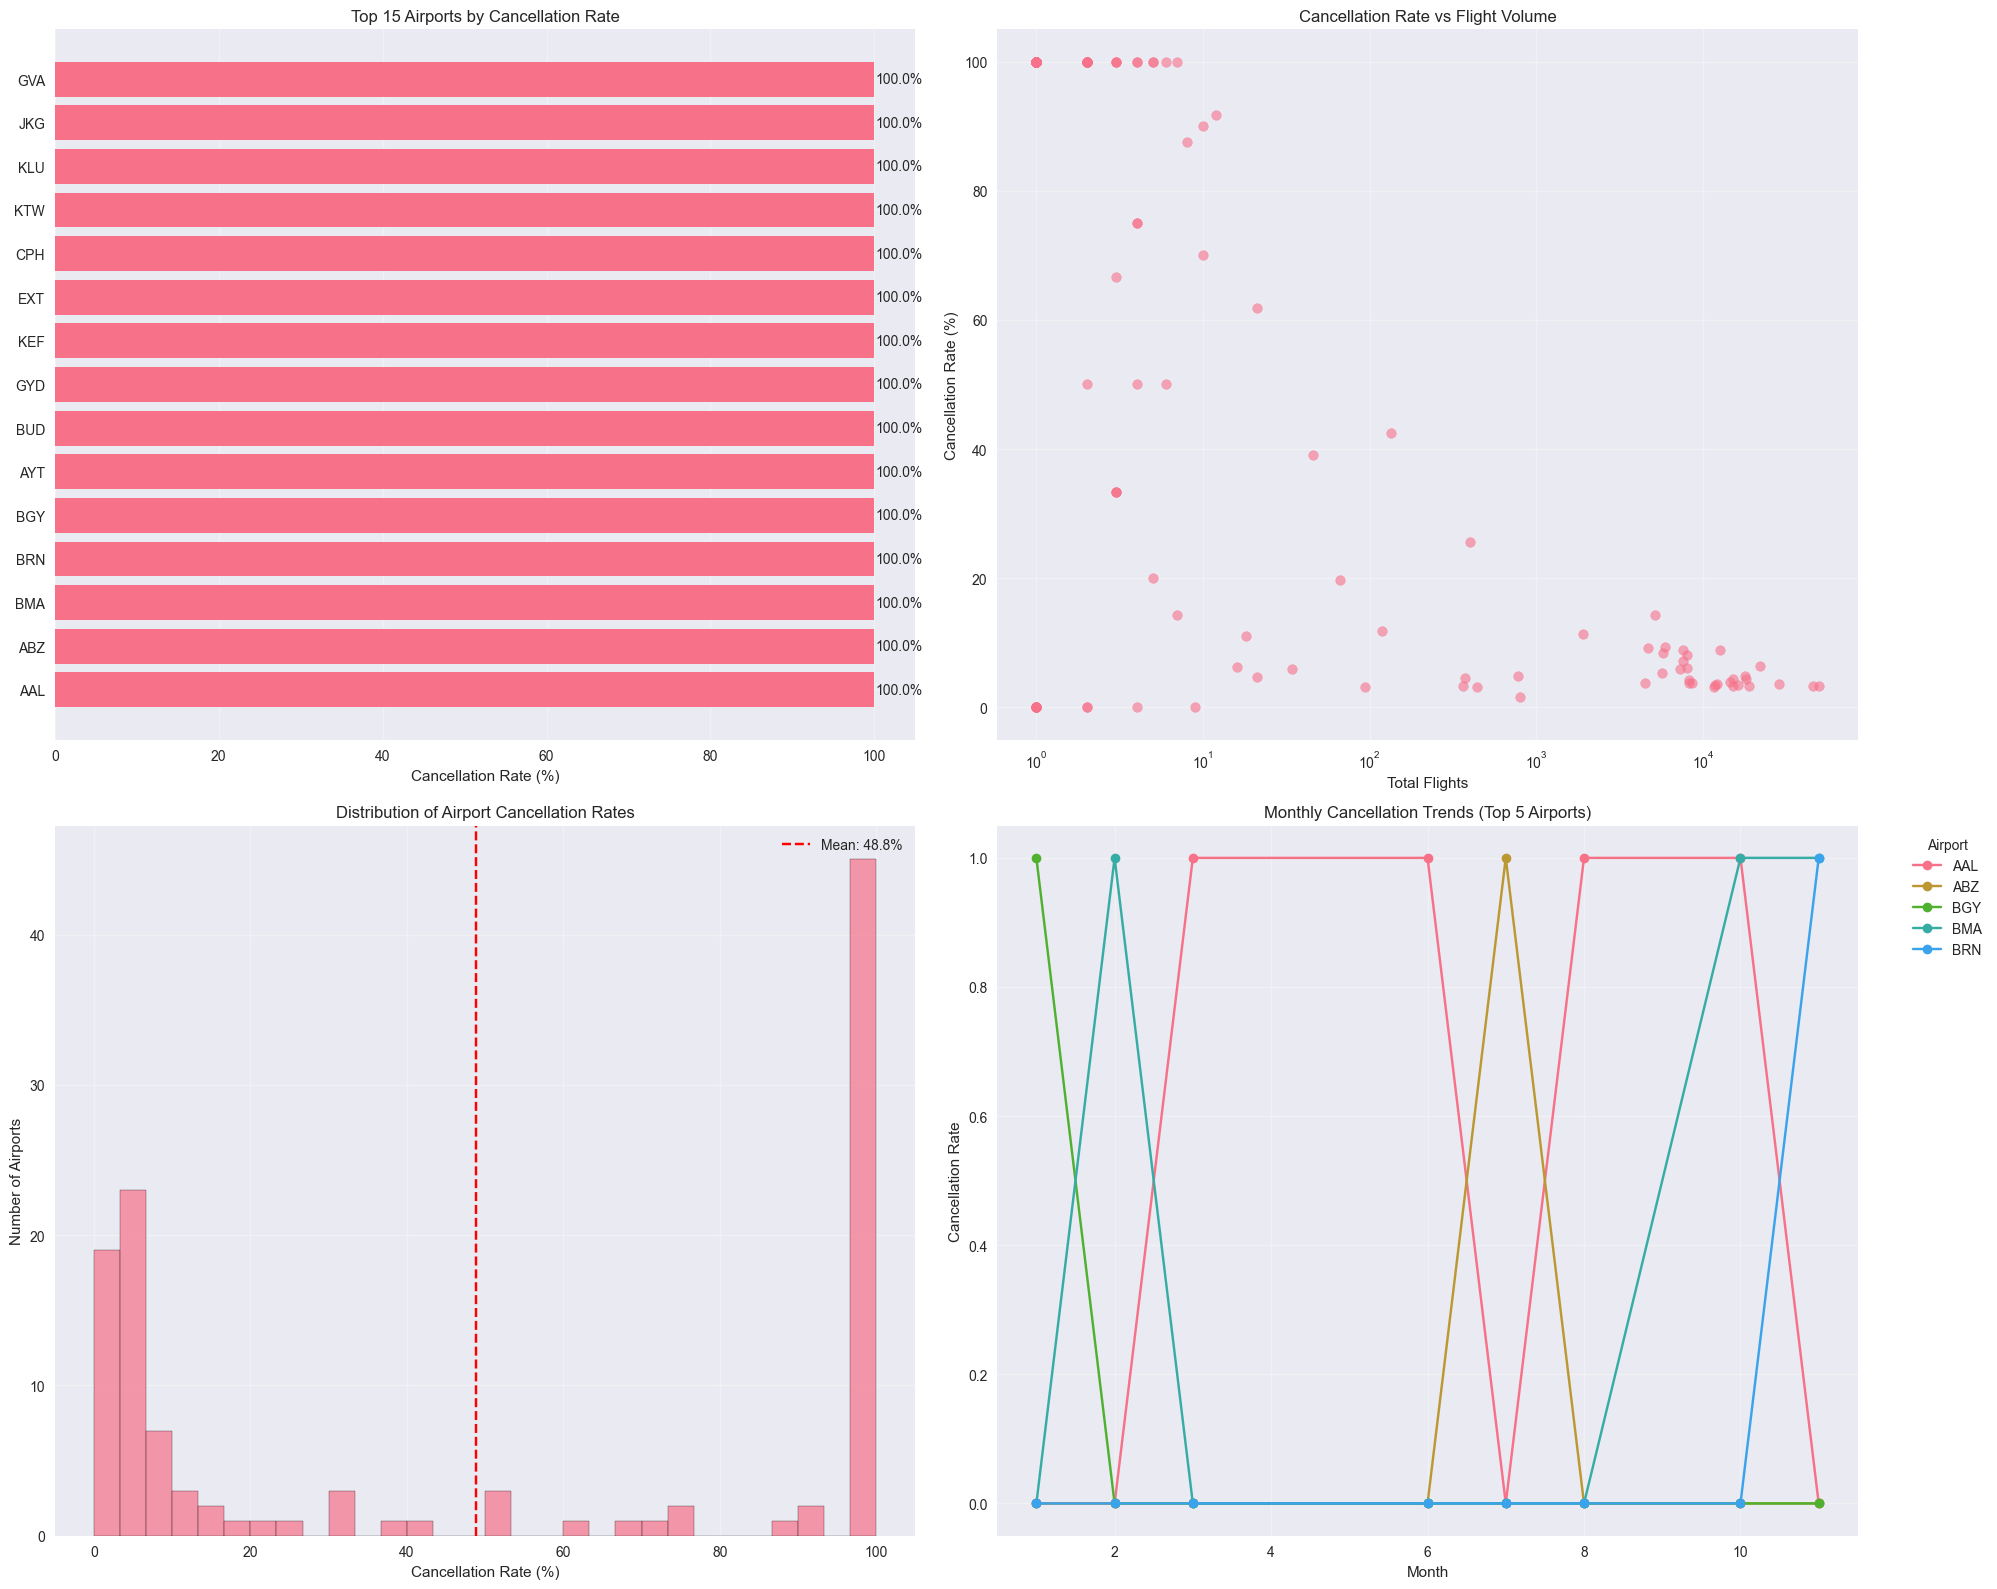

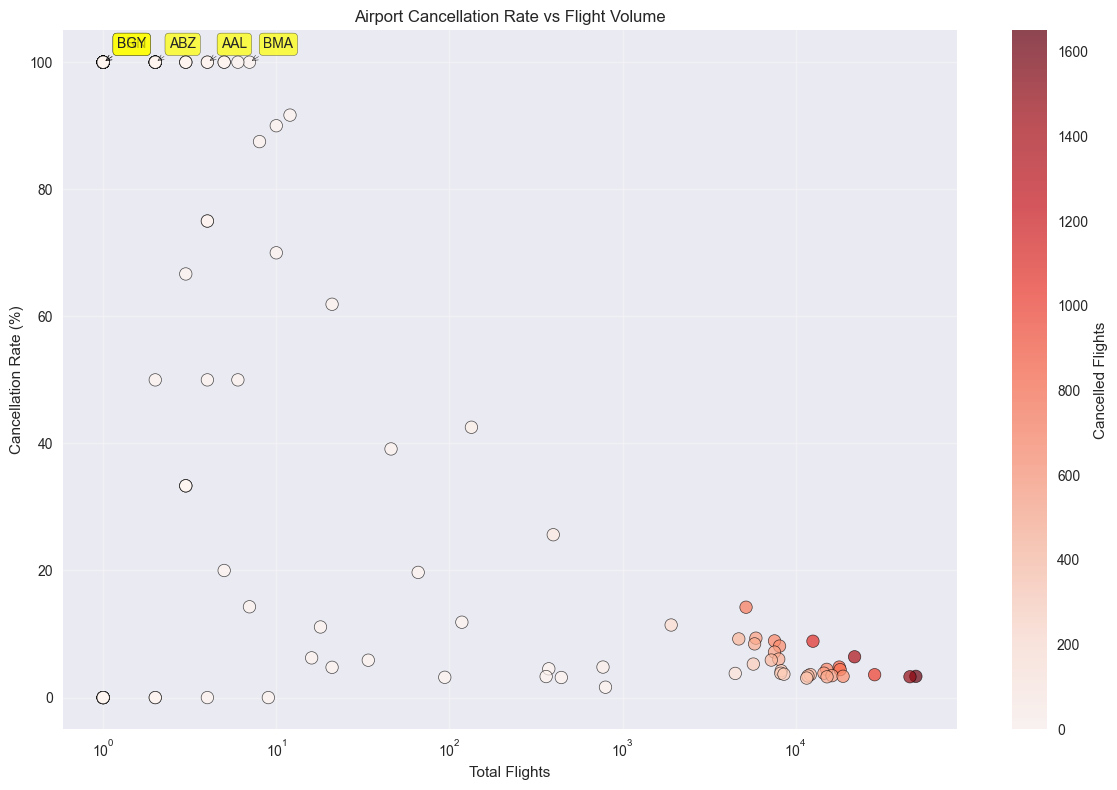


📊 Top 5 airports with highest cancellation rates:
   1. AAL: 100.0% (4/4 flights)
   2. ABZ: 100.0% (2/2 flights)
   3. BMA: 100.0% (7/7 flights)
   4. BRN: 100.0% (1/1 flights)
   5. BGY: 100.0% (1/1 flights)


In [ ]:
# Airport-based Cancellation Analysis
print("🏢 AIRPORT CANCELLATION ANALYSIS")
print("=" * 40)

# Calculate cancellation rates by departure airport
airport_stats = (
    df_flights.groupby("dep_airport")
    .agg({"is_cancelled": ["count", "sum", "mean"], "std": ["min", "max"]})
    .round(4)
)

airport_stats.columns = [
    "total_flights",
    "cancelled_flights",
    "cancellation_rate",
    "first_flight",
    "last_flight",
]
airport_stats = airport_stats.sort_values("cancellation_rate", ascending=False)

print(f"📊 Top 10 airports by cancellation rate:")
print(airport_stats.head(10))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# 1. Top airports by cancellation rate
top_airports = airport_stats.head(15)
axes[0, 0].barh(range(len(top_airports)), top_airports["cancellation_rate"] * 100)
axes[0, 0].set_yticks(range(len(top_airports)))
axes[0, 0].set_yticklabels(top_airports.index)
axes[0, 0].set_xlabel("Cancellation Rate (%)")
axes[0, 0].set_title("Top 15 Airports by Cancellation Rate")
axes[0, 0].grid(True, alpha=0.3)

# Add value labels
for i, v in enumerate(top_airports["cancellation_rate"] * 100):
    axes[0, 0].text(v + 0.1, i, f"{v:.1f}%", va="center")

# 2. Cancellation rate vs flight volume
axes[0, 1].scatter(
    airport_stats["total_flights"], airport_stats["cancellation_rate"] * 100, alpha=0.6
)
axes[0, 1].set_xlabel("Total Flights")
axes[0, 1].set_ylabel("Cancellation Rate (%)")
axes[0, 1].set_title("Cancellation Rate vs Flight Volume")
axes[0, 1].set_xscale("log")
axes[0, 1].grid(True, alpha=0.3)

# 3. Distribution of cancellation rates
axes[1, 0].hist(
    airport_stats["cancellation_rate"] * 100, bins=30, alpha=0.7, edgecolor="black"
)
axes[1, 0].set_xlabel("Cancellation Rate (%)")
axes[1, 0].set_ylabel("Number of Airports")
axes[1, 0].set_title("Distribution of Airport Cancellation Rates")
axes[1, 0].axvline(
    airport_stats["cancellation_rate"].mean() * 100,
    color="red",
    linestyle="--",
    label=f'Mean: {airport_stats["cancellation_rate"].mean()*100:.1f}%',
)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Monthly cancellation trends by top airports
df_flights["month"] = df_flights["std"].dt.month
top_5_airports = airport_stats.head(5).index

monthly_data = (
    df_flights[df_flights["dep_airport"].isin(top_5_airports)]
    .groupby(["dep_airport", "month"])["is_cancelled"]
    .mean()
    .unstack(fill_value=0)
)

monthly_data.T.plot(kind="line", ax=axes[1, 1], marker="o")
axes[1, 1].set_xlabel("Month")
axes[1, 1].set_ylabel("Cancellation Rate")
axes[1, 1].set_title("Monthly Cancellation Trends (Top 5 Airports)")
axes[1, 1].legend(title="Airport", bbox_to_anchor=(1.05, 1), loc="upper left")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Enhanced matplotlib visualization instead of plotly
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

# Create enhanced scatter plot with annotations
scatter = ax.scatter(
    airport_stats["total_flights"],
    airport_stats["cancellation_rate"] * 100,
    alpha=0.7,
    s=80,
    c=airport_stats["cancelled_flights"],
    cmap="Reds",
    edgecolors="black",
    linewidth=0.5,
)

ax.set_xlabel("Total Flights")
ax.set_ylabel("Cancellation Rate (%)")
ax.set_title("Airport Cancellation Rate vs Flight Volume")
ax.set_xscale("log")
ax.grid(True, alpha=0.3)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Cancelled Flights")

# Annotate top 5 worst airports
top_5_worst = airport_stats.head(5)
for idx, (airport, data) in enumerate(top_5_worst.iterrows()):
    ax.annotate(
        airport,
        (data["total_flights"], data["cancellation_rate"] * 100),
        xytext=(10, 10),
        textcoords="offset points",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.7),
        arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0"),
    )

plt.tight_layout()
plt.show()

print(f"\n📊 Top 5 airports with highest cancellation rates:")
for i, (airport, data) in enumerate(top_5_worst.iterrows(), 1):
    print(
        f"   {i}. {airport}: {data['cancellation_rate']*100:.1f}% ({data['cancelled_flights']:.0f}/{data['total_flights']:.0f} flights)"
    )

⏰ TEMPORAL CANCELLATION PATTERNS
📊 Temporal Cancellation Statistics:

HOURLY:
      count   sum   mean
hour                    
0        26    12  46.15
1         9     7  77.78
2       947    61   6.44
3      7122   493   6.92
4     20013  1199   5.99
5     22626  1260   5.57
6     25542  1237   4.84
7     27715  1223   4.41
8     19857   972   4.89
9     18135   637   3.51
10    20596   703   3.41
11    21955   680   3.10
12    18852   605   3.21
13    18453   516   2.80
14    21241   802   3.78
15    25167  1193   4.74
16    29299  1293   4.41
17    26739  1243   4.65
18    23497  1098   4.67
19    23348  1421   6.09
20    20698  1368   6.61
21    12976   980   7.55
22     4800   491  10.23
23      829    80   9.65

DAILY:
           count   sum  mean
day_name                    
Friday     68573  3217  4.69
Monday     69548  3649  5.25
Saturday   17202   544  3.16
Sunday     47421  2117  4.46
Thursday   68443  3224  4.71
Tuesday    69165  3446  4.98
Wednesday  70090  3377  4.82

MO

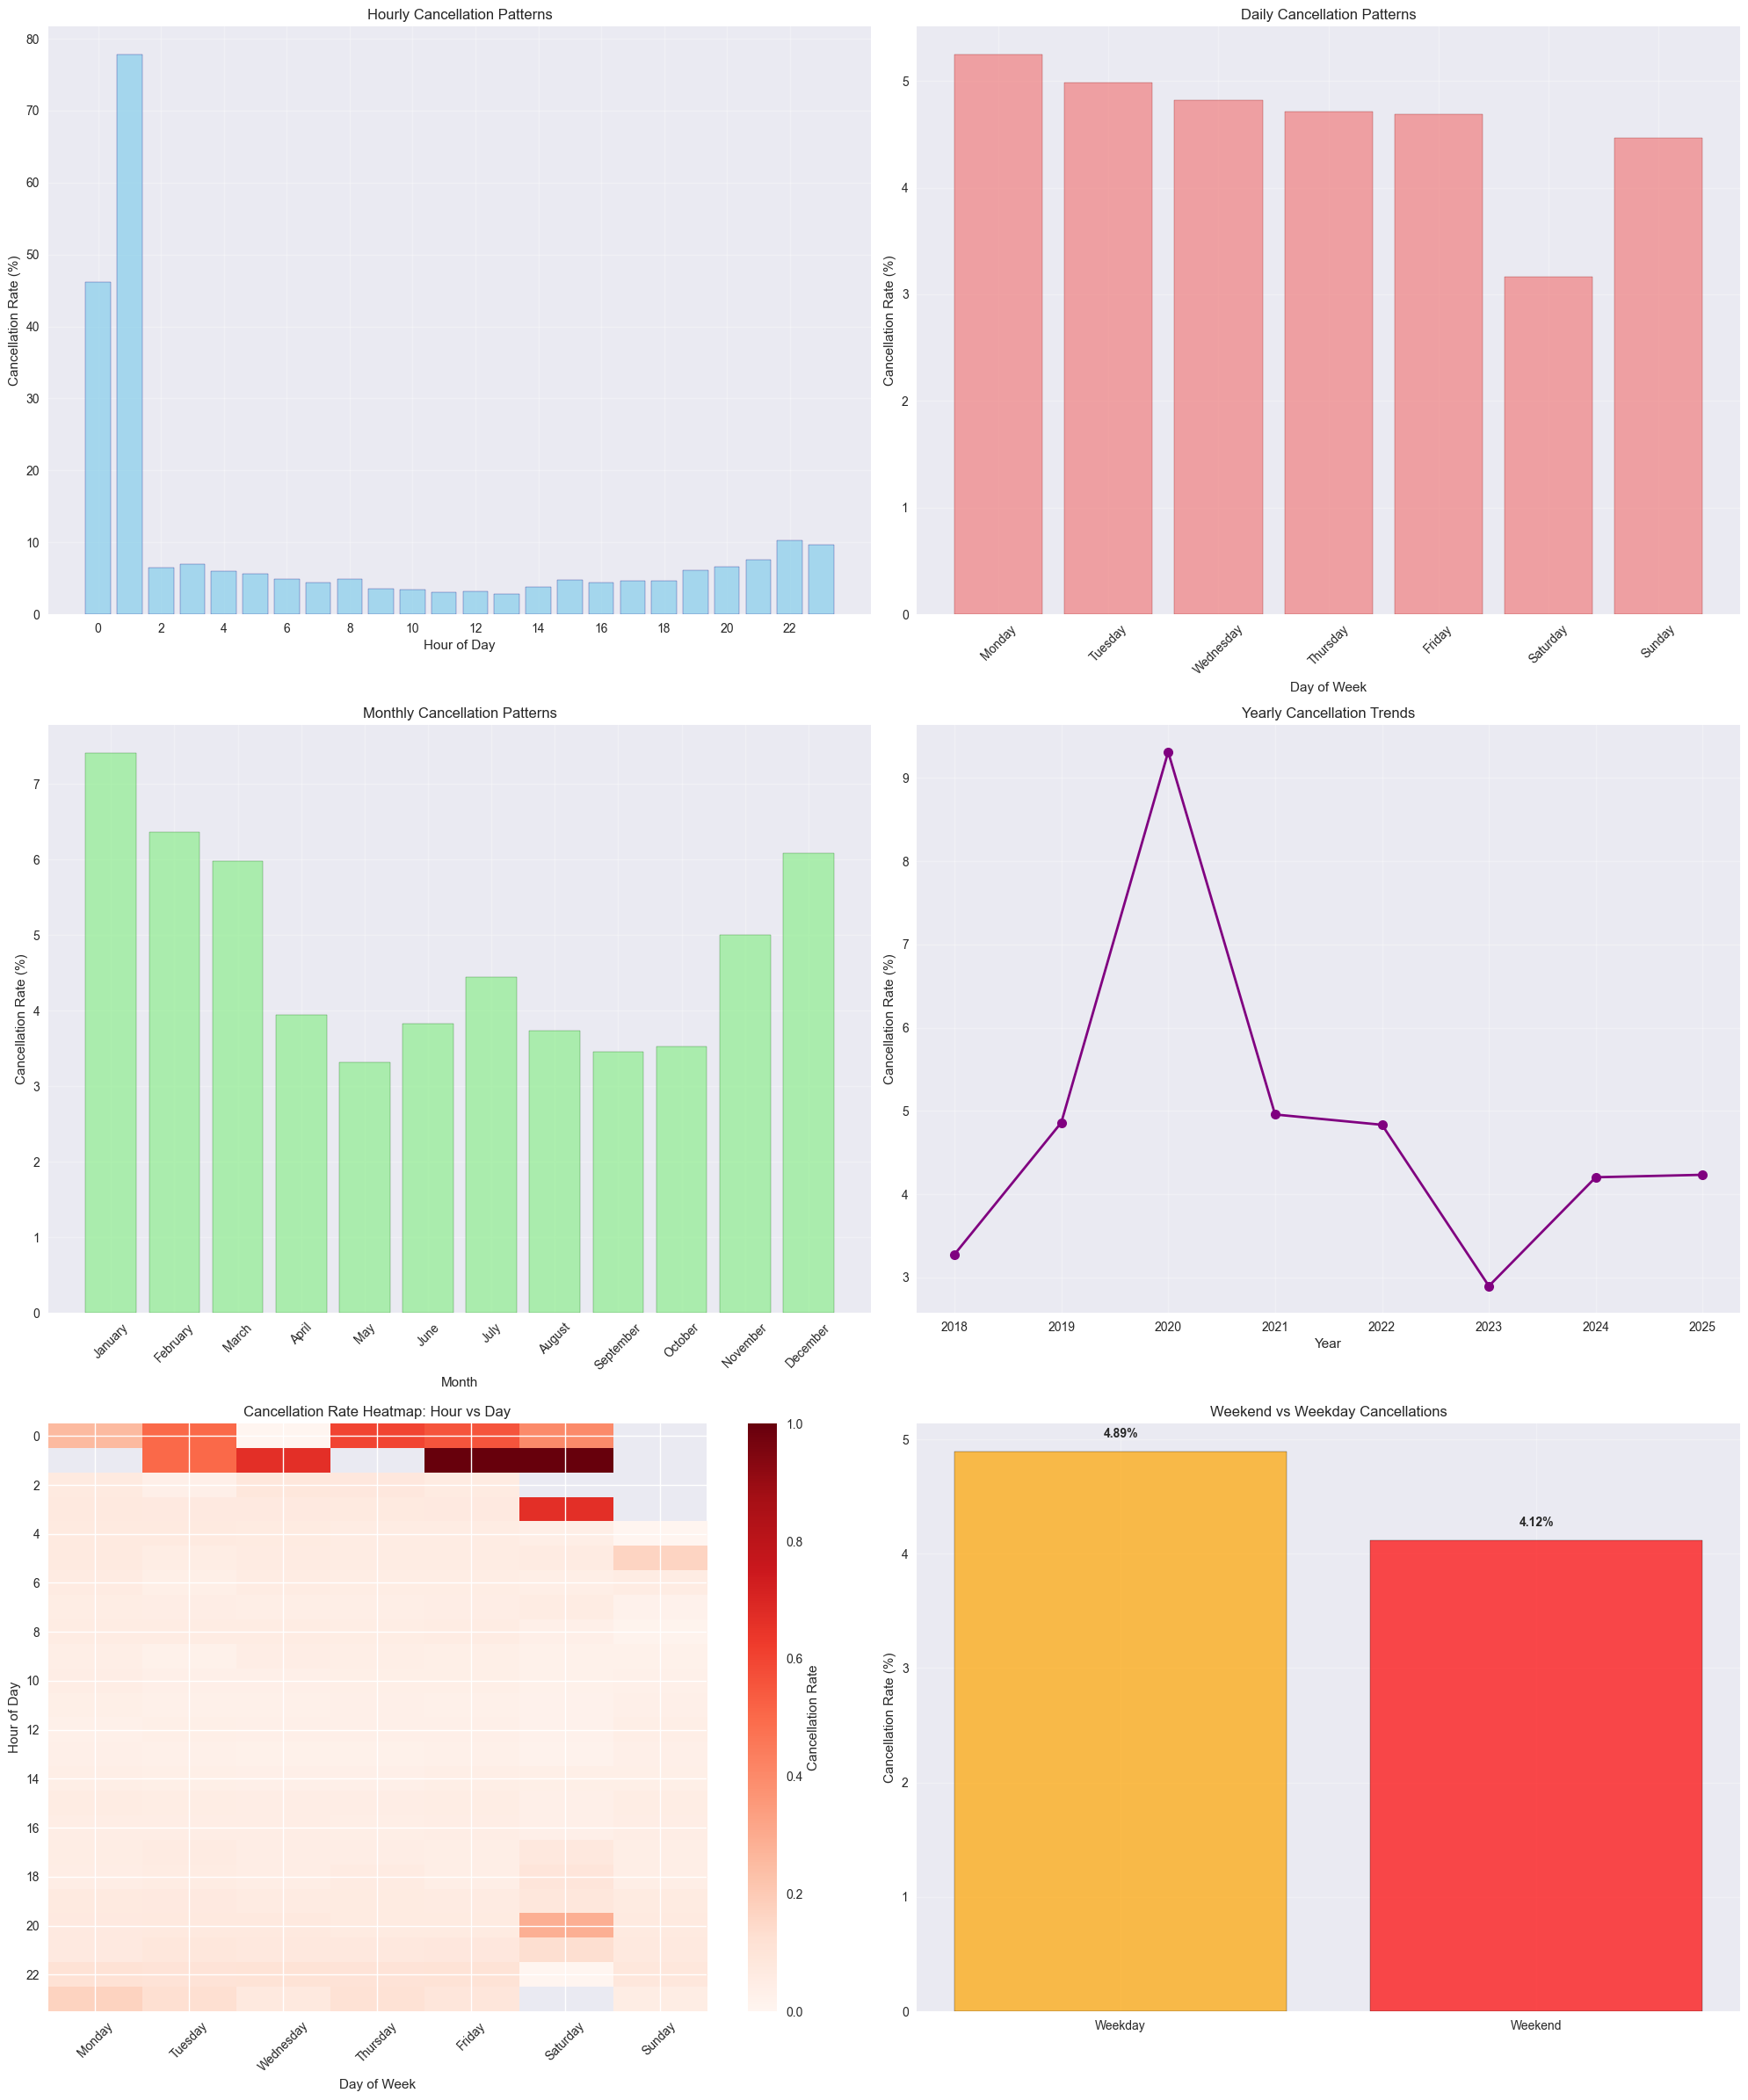


📈 Statistical Tests:
Weekend vs Weekday t-test: t=-8.464, p=0.000000
Significant difference: Yes


In [ ]:
# Temporal Pattern Analysis
print("⏰ TEMPORAL CANCELLATION PATTERNS")
print("=" * 40)

# Extract temporal features
df_flights["hour"] = df_flights["std"].dt.hour
df_flights["day_of_week"] = df_flights["std"].dt.dayofweek
df_flights["day_name"] = df_flights["std"].dt.day_name()
df_flights["month"] = df_flights["std"].dt.month
df_flights["month_name"] = df_flights["std"].dt.month_name()
df_flights["year"] = df_flights["std"].dt.year
df_flights["quarter"] = df_flights["std"].dt.quarter
df_flights["is_weekend"] = df_flights["day_of_week"].isin([5, 6])

# Calculate temporal statistics
temporal_stats = {
    "hourly": df_flights.groupby("hour")["is_cancelled"].agg(["count", "sum", "mean"]),
    "daily": df_flights.groupby("day_name")["is_cancelled"].agg(
        ["count", "sum", "mean"]
    ),
    "monthly": df_flights.groupby("month_name")["is_cancelled"].agg(
        ["count", "sum", "mean"]
    ),
    "yearly": df_flights.groupby("year")["is_cancelled"].agg(["count", "sum", "mean"]),
    "quarterly": df_flights.groupby("quarter")["is_cancelled"].agg(
        ["count", "sum", "mean"]
    ),
}

print("📊 Temporal Cancellation Statistics:")
for period, stats in temporal_stats.items():
    print(f"\n{period.upper()}:")
    stats_formatted = stats.copy()
    stats_formatted["mean"] = stats_formatted["mean"] * 100
    print(stats_formatted.round(2))

# Create comprehensive temporal visualizations
fig, axes = plt.subplots(3, 2, figsize=(20, 24))

# 1. Hourly patterns
hourly_stats = temporal_stats["hourly"]
axes[0, 0].bar(
    hourly_stats.index,
    hourly_stats["mean"] * 100,
    alpha=0.7,
    color="skyblue",
    edgecolor="navy",
)
axes[0, 0].set_xlabel("Hour of Day")
axes[0, 0].set_ylabel("Cancellation Rate (%)")
axes[0, 0].set_title("Hourly Cancellation Patterns")
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xticks(range(0, 24, 2))

# 2. Day of week patterns
daily_stats = temporal_stats["daily"]
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
daily_reordered = daily_stats.reindex(day_order)
axes[0, 1].bar(
    range(len(daily_reordered)),
    daily_reordered["mean"] * 100,
    alpha=0.7,
    color="lightcoral",
    edgecolor="darkred",
)
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel("Cancellation Rate (%)")
axes[0, 1].set_title("Daily Cancellation Patterns")
axes[0, 1].set_xticks(range(len(day_order)))
axes[0, 1].set_xticklabels(day_order, rotation=45)
axes[0, 1].grid(True, alpha=0.3)

# 3. Monthly patterns
monthly_stats = temporal_stats["monthly"]
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]
monthly_reordered = monthly_stats.reindex(month_order)
axes[1, 0].bar(
    range(len(monthly_reordered)),
    monthly_reordered["mean"] * 100,
    alpha=0.7,
    color="lightgreen",
    edgecolor="darkgreen",
)
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Cancellation Rate (%)")
axes[1, 0].set_title("Monthly Cancellation Patterns")
axes[1, 0].set_xticks(range(len(month_order)))
axes[1, 0].set_xticklabels(month_order, rotation=45)
axes[1, 0].grid(True, alpha=0.3)

# 4. Yearly trends
yearly_stats = temporal_stats["yearly"]
axes[1, 1].plot(
    yearly_stats.index,
    yearly_stats["mean"] * 100,
    marker="o",
    linewidth=2,
    markersize=8,
    color="purple",
)
axes[1, 1].set_xlabel("Year")
axes[1, 1].set_ylabel("Cancellation Rate (%)")
axes[1, 1].set_title("Yearly Cancellation Trends")
axes[1, 1].grid(True, alpha=0.3)

# 5. Heatmap: Hour vs Day of Week
pivot_hourly_daily = df_flights.pivot_table(
    values="is_cancelled", index="hour", columns="day_name", aggfunc="mean"
)
pivot_hourly_daily = pivot_hourly_daily.reindex(columns=day_order)
im = axes[2, 0].imshow(pivot_hourly_daily.values, cmap="Reds", aspect="auto")
axes[2, 0].set_xticks(range(len(day_order)))
axes[2, 0].set_xticklabels(day_order, rotation=45)
axes[2, 0].set_yticks(range(0, 24, 2))
axes[2, 0].set_yticklabels(range(0, 24, 2))
axes[2, 0].set_xlabel("Day of Week")
axes[2, 0].set_ylabel("Hour of Day")
axes[2, 0].set_title("Cancellation Rate Heatmap: Hour vs Day")
plt.colorbar(im, ax=axes[2, 0], label="Cancellation Rate")

# 6. Weekend vs Weekday comparison
weekend_stats = df_flights.groupby("is_weekend")["is_cancelled"].agg(
    ["count", "sum", "mean"]
)
weekend_labels = ["Weekday", "Weekend"]
axes[2, 1].bar(
    weekend_labels,
    weekend_stats["mean"] * 100,
    alpha=0.7,
    color=["orange", "red"],
    edgecolor="black",
)
axes[2, 1].set_ylabel("Cancellation Rate (%)")
axes[2, 1].set_title("Weekend vs Weekday Cancellations")
axes[2, 1].grid(True, alpha=0.3)

# Add value labels
for i, v in enumerate(weekend_stats["mean"] * 100):
    axes[2, 1].text(
        i, v + 0.1, f"{v:.2f}%", ha="center", va="bottom", fontweight="bold"
    )

plt.tight_layout()
plt.show()

# Statistical significance tests
from scipy.stats import chi2_contingency, ttest_ind

# Test weekend vs weekday difference
weekend_cancelled = df_flights[df_flights["is_weekend"]]["is_cancelled"]
weekday_cancelled = df_flights[~df_flights["is_weekend"]]["is_cancelled"]
t_stat, p_value = ttest_ind(weekend_cancelled, weekday_cancelled)

print(f"\n📈 Statistical Tests:")
print(f"Weekend vs Weekday t-test: t={t_stat:.3f}, p={p_value:.6f}")
print(f"Significant difference: {'Yes' if p_value < 0.05 else 'No'}")

🌤️ WEATHER-CANCELLATION CORRELATION ANALYSIS
🔗 Merging flight and weather data...
   • Weather data coverage: 32.8%
   • Flights with weather: 134,464

📊 Weather Statistics for 134,464 flights:
              temperature_c  humidity_percent  precipitation_mm  pressure_hpa  \
is_cancelled                                                                    
False                  4.57             80.06              0.16       1000.58   
True                   2.89             81.53              0.21        998.43   

              cloud_cover_percent  wind_speed_kmh  visibility  
is_cancelled                                                   
False                       76.38           14.33         NaN  
True                        79.91           18.10         NaN  
   • Weather data coverage: 32.8%
   • Flights with weather: 134,464

📊 Weather Statistics for 134,464 flights:
              temperature_c  humidity_percent  precipitation_mm  pressure_hpa  \
is_cancelled                    

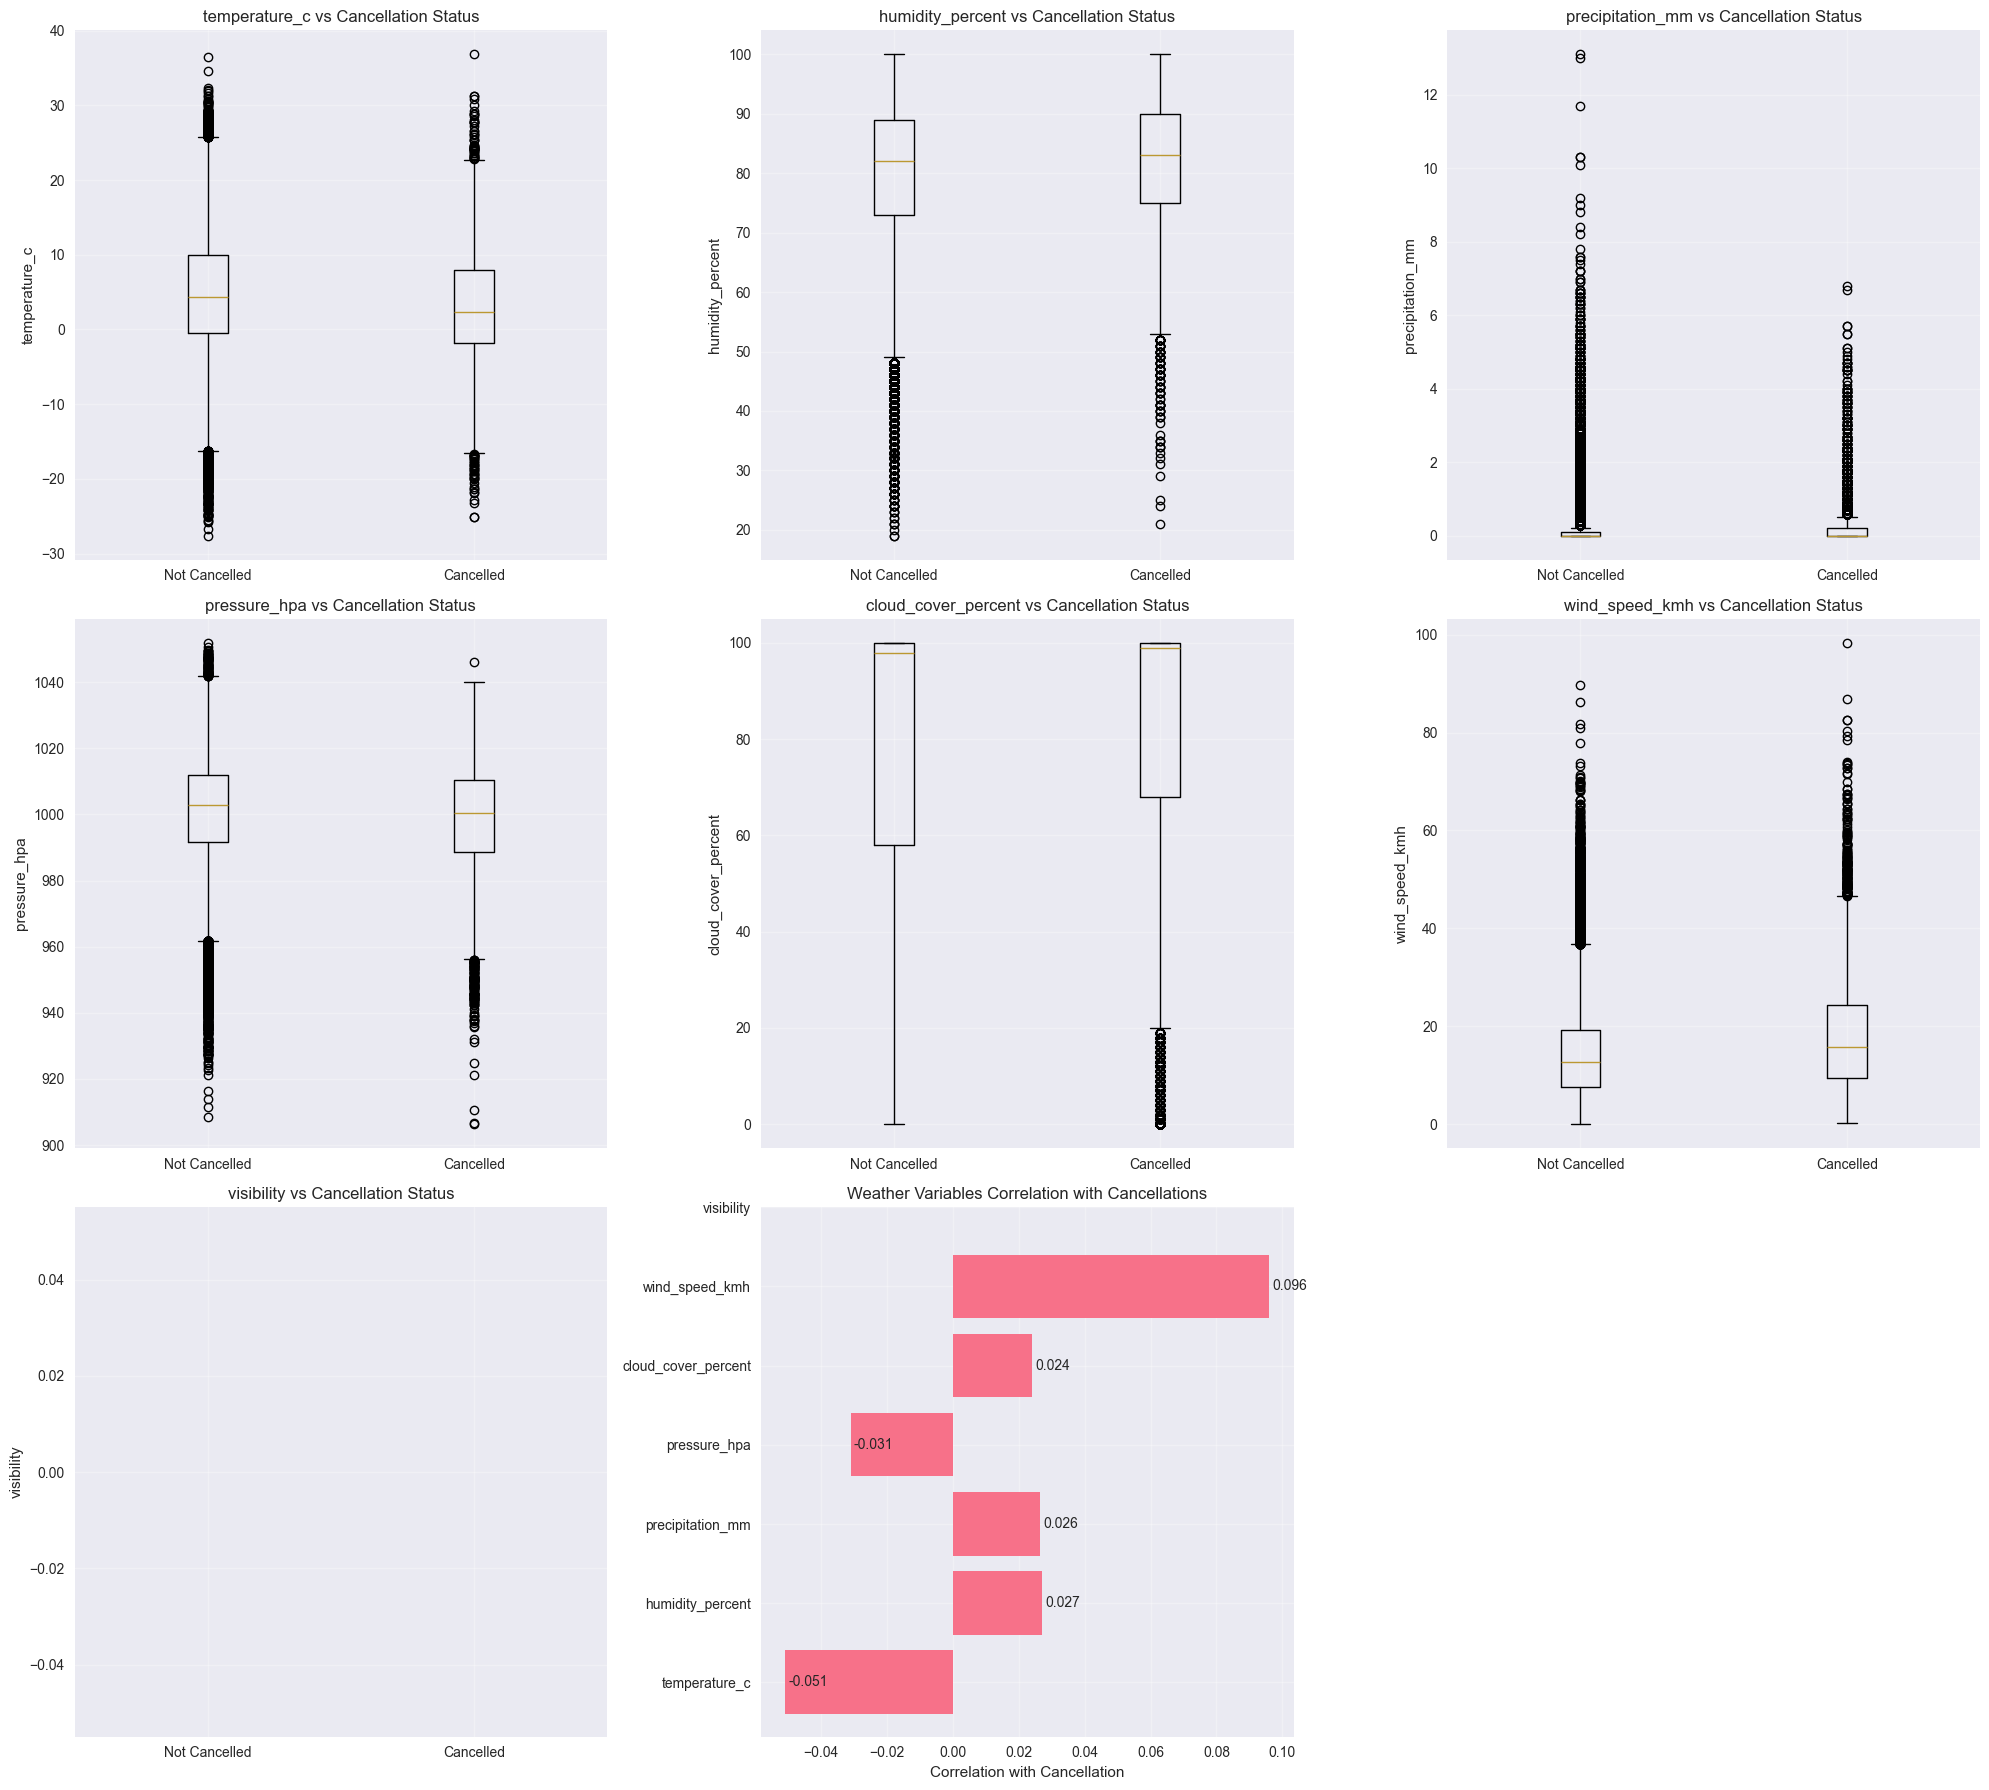


📈 Statistical Tests for Weather Impact:
temperature_c: t=-18.712, p=0.000000, significant=Yes
humidity_percent: t=9.904, p=0.000000, significant=Yes
precipitation_mm: t=9.713, p=0.000000, significant=Yes
pressure_hpa: t=-11.401, p=0.000000, significant=Yes
cloud_cover_percent: t=8.805, p=0.000000, significant=Yes
wind_speed_kmh: t=35.384, p=0.000000, significant=Yes

Severe weather vs cancellation: χ²=136.441, p=0.000000

Severe weather vs cancellation: χ²=136.441, p=0.000000


In [ ]:
# Weather-Cancellation Correlation Analysis
print("🌤️ WEATHER-CANCELLATION CORRELATION ANALYSIS")
print("=" * 50)

if not df_weather.empty:
    # Prepare weather data for merging
    print("🔗 Merging flight and weather data...")

    # Create matching keys for flights and weather
    df_flights["flight_date_hour"] = df_flights["std"].dt.floor("H")
    df_weather["weather_key"] = (
        df_weather["airport"].astype(str)
        + "_"
        + df_weather["datetime"].dt.strftime("%Y-%m-%d_%H")
    )
    df_flights["flight_key"] = (
        df_flights["dep_airport"].astype(str)
        + "_"
        + df_flights["flight_date_hour"].dt.strftime("%Y-%m-%d_%H")
    )

    # Merge flights with weather data
    df_merged = df_flights.merge(
        df_weather[
            [
                "weather_key",
                "temperature_c",
                "humidity_percent",
                "precipitation_mm",
                "pressure_hpa",
                "cloud_cover_percent",
                "wind_speed_kmh",
                "visibility",
            ]
        ],
        left_on="flight_key",
        right_on="weather_key",
        how="left",
    )

    weather_coverage = (df_merged["weather_key"].notna().sum() / len(df_merged)) * 100
    print(f"   • Weather data coverage: {weather_coverage:.1f}%")
    print(f"   • Flights with weather: {df_merged['weather_key'].notna().sum():,}")

    if weather_coverage > 5:  # Only proceed if we have reasonable weather coverage
        # Filter to flights with weather data
        df_weather_flights = df_merged[df_merged["weather_key"].notna()].copy()

        # Weather-based cancellation analysis
        weather_vars = [
            "temperature_c",
            "humidity_percent",
            "precipitation_mm",
            "pressure_hpa",
            "cloud_cover_percent",
            "wind_speed_kmh",
            "visibility",
        ]

        print(f"\n📊 Weather Statistics for {len(df_weather_flights):,} flights:")
        weather_stats = df_weather_flights.groupby("is_cancelled")[weather_vars].mean()
        print(weather_stats.round(2))

        # Create weather correlation visualizations
        fig, axes = plt.subplots(3, 3, figsize=(20, 18))
        axes = axes.flatten()

        for i, var in enumerate(weather_vars):
            if i < len(axes):
                # Box plots comparing cancelled vs non-cancelled flights
                data_to_plot = [
                    df_weather_flights[~df_weather_flights["is_cancelled"]][
                        var
                    ].dropna(),
                    df_weather_flights[df_weather_flights["is_cancelled"]][
                        var
                    ].dropna(),
                ]

                axes[i].boxplot(data_to_plot, labels=["Not Cancelled", "Cancelled"])
                axes[i].set_title(f"{var} vs Cancellation Status")
                axes[i].set_ylabel(var)
                axes[i].grid(True, alpha=0.3)

        # Weather severity categories
        df_weather_flights["severe_weather"] = (
            (df_weather_flights["precipitation_mm"] > 5)
            | (df_weather_flights["wind_speed_kmh"] > 30)
            | (df_weather_flights["visibility"] < 5000)
            | (df_weather_flights["cloud_cover_percent"] > 90)
        )

        # Extreme weather conditions
        df_weather_flights["extreme_weather"] = (
            (df_weather_flights["precipitation_mm"] > 10)
            | (df_weather_flights["wind_speed_kmh"] > 50)
            | (df_weather_flights["visibility"] < 1000)
        )

        # Weather condition impact
        weather_impact = (
            df_weather_flights.groupby(["severe_weather", "is_cancelled"])
            .size()
            .unstack(fill_value=0)
        )
        weather_impact_pct = (
            weather_impact.div(weather_impact.sum(axis=1), axis=0) * 100
        )

        print(f"\n🌧️ Weather Impact Analysis:")
        print("Cancellation rates by weather conditions:")
        print(weather_impact_pct.round(2))

        # Weather correlation heatmap
        if len(axes) > len(weather_vars):
            weather_corr = (
                df_weather_flights[weather_vars + ["is_cancelled"]]
                .corr()["is_cancelled"]
                .drop("is_cancelled")
            )

            axes[len(weather_vars)].barh(range(len(weather_corr)), weather_corr.values)
            axes[len(weather_vars)].set_yticks(range(len(weather_corr)))
            axes[len(weather_vars)].set_yticklabels(weather_corr.index)
            axes[len(weather_vars)].set_xlabel("Correlation with Cancellation")
            axes[len(weather_vars)].set_title(
                "Weather Variables Correlation with Cancellations"
            )
            axes[len(weather_vars)].grid(True, alpha=0.3)

            # Add correlation values as text
            for i, v in enumerate(weather_corr.values):
                axes[len(weather_vars)].text(v + 0.001, i, f"{v:.3f}", va="center")

        # Remove unused subplots
        for i in range(len(weather_vars) + 1, len(axes)):
            fig.delaxes(axes[i])

        plt.tight_layout()
        plt.show()

        # Statistical tests for weather impact
        print(f"\n📈 Statistical Tests for Weather Impact:")
        for var in weather_vars:
            cancelled_weather = df_weather_flights[df_weather_flights["is_cancelled"]][
                var
            ].dropna()
            not_cancelled_weather = df_weather_flights[
                ~df_weather_flights["is_cancelled"]
            ][var].dropna()

            if len(cancelled_weather) > 0 and len(not_cancelled_weather) > 0:
                t_stat, p_value = ttest_ind(cancelled_weather, not_cancelled_weather)
                print(
                    f"{var}: t={t_stat:.3f}, p={p_value:.6f}, significant={'Yes' if p_value < 0.05 else 'No'}"
                )

        # Severe weather impact
        severe_weather_crosstab = pd.crosstab(
            df_weather_flights["severe_weather"], df_weather_flights["is_cancelled"]
        )
        chi2, p_val, dof, expected = chi2_contingency(severe_weather_crosstab)
        print(f"\nSevere weather vs cancellation: χ²={chi2:.3f}, p={p_val:.6f}")

    else:
        print("⚠️ Insufficient weather data coverage for meaningful analysis")

else:
    print("❌ No weather data available for correlation analysis")

✈️ FLIGHT CHARACTERISTICS & ROUTE ANALYSIS
🛩️ Aircraft-related columns: ['service_type']

📊 Top aircraft types by cancellation rate:
              total_flights  cancelled_flights  cancellation_rate
service_type                                                     
A                         2                  2           1.000000
X                         2                  2           1.000000
I                         4                  4           1.000000
W                        13                 13           1.000000
U                         1                  1           1.000000
Y                         1                  1           1.000000
E                       199                186           0.934673
D                        57                 49           0.859649
F                         6                  5           0.833333
G                         4                  3           0.750000

🛣️ Route Analysis:
Top 10 routes by cancellation rate (min 10 flights):
  

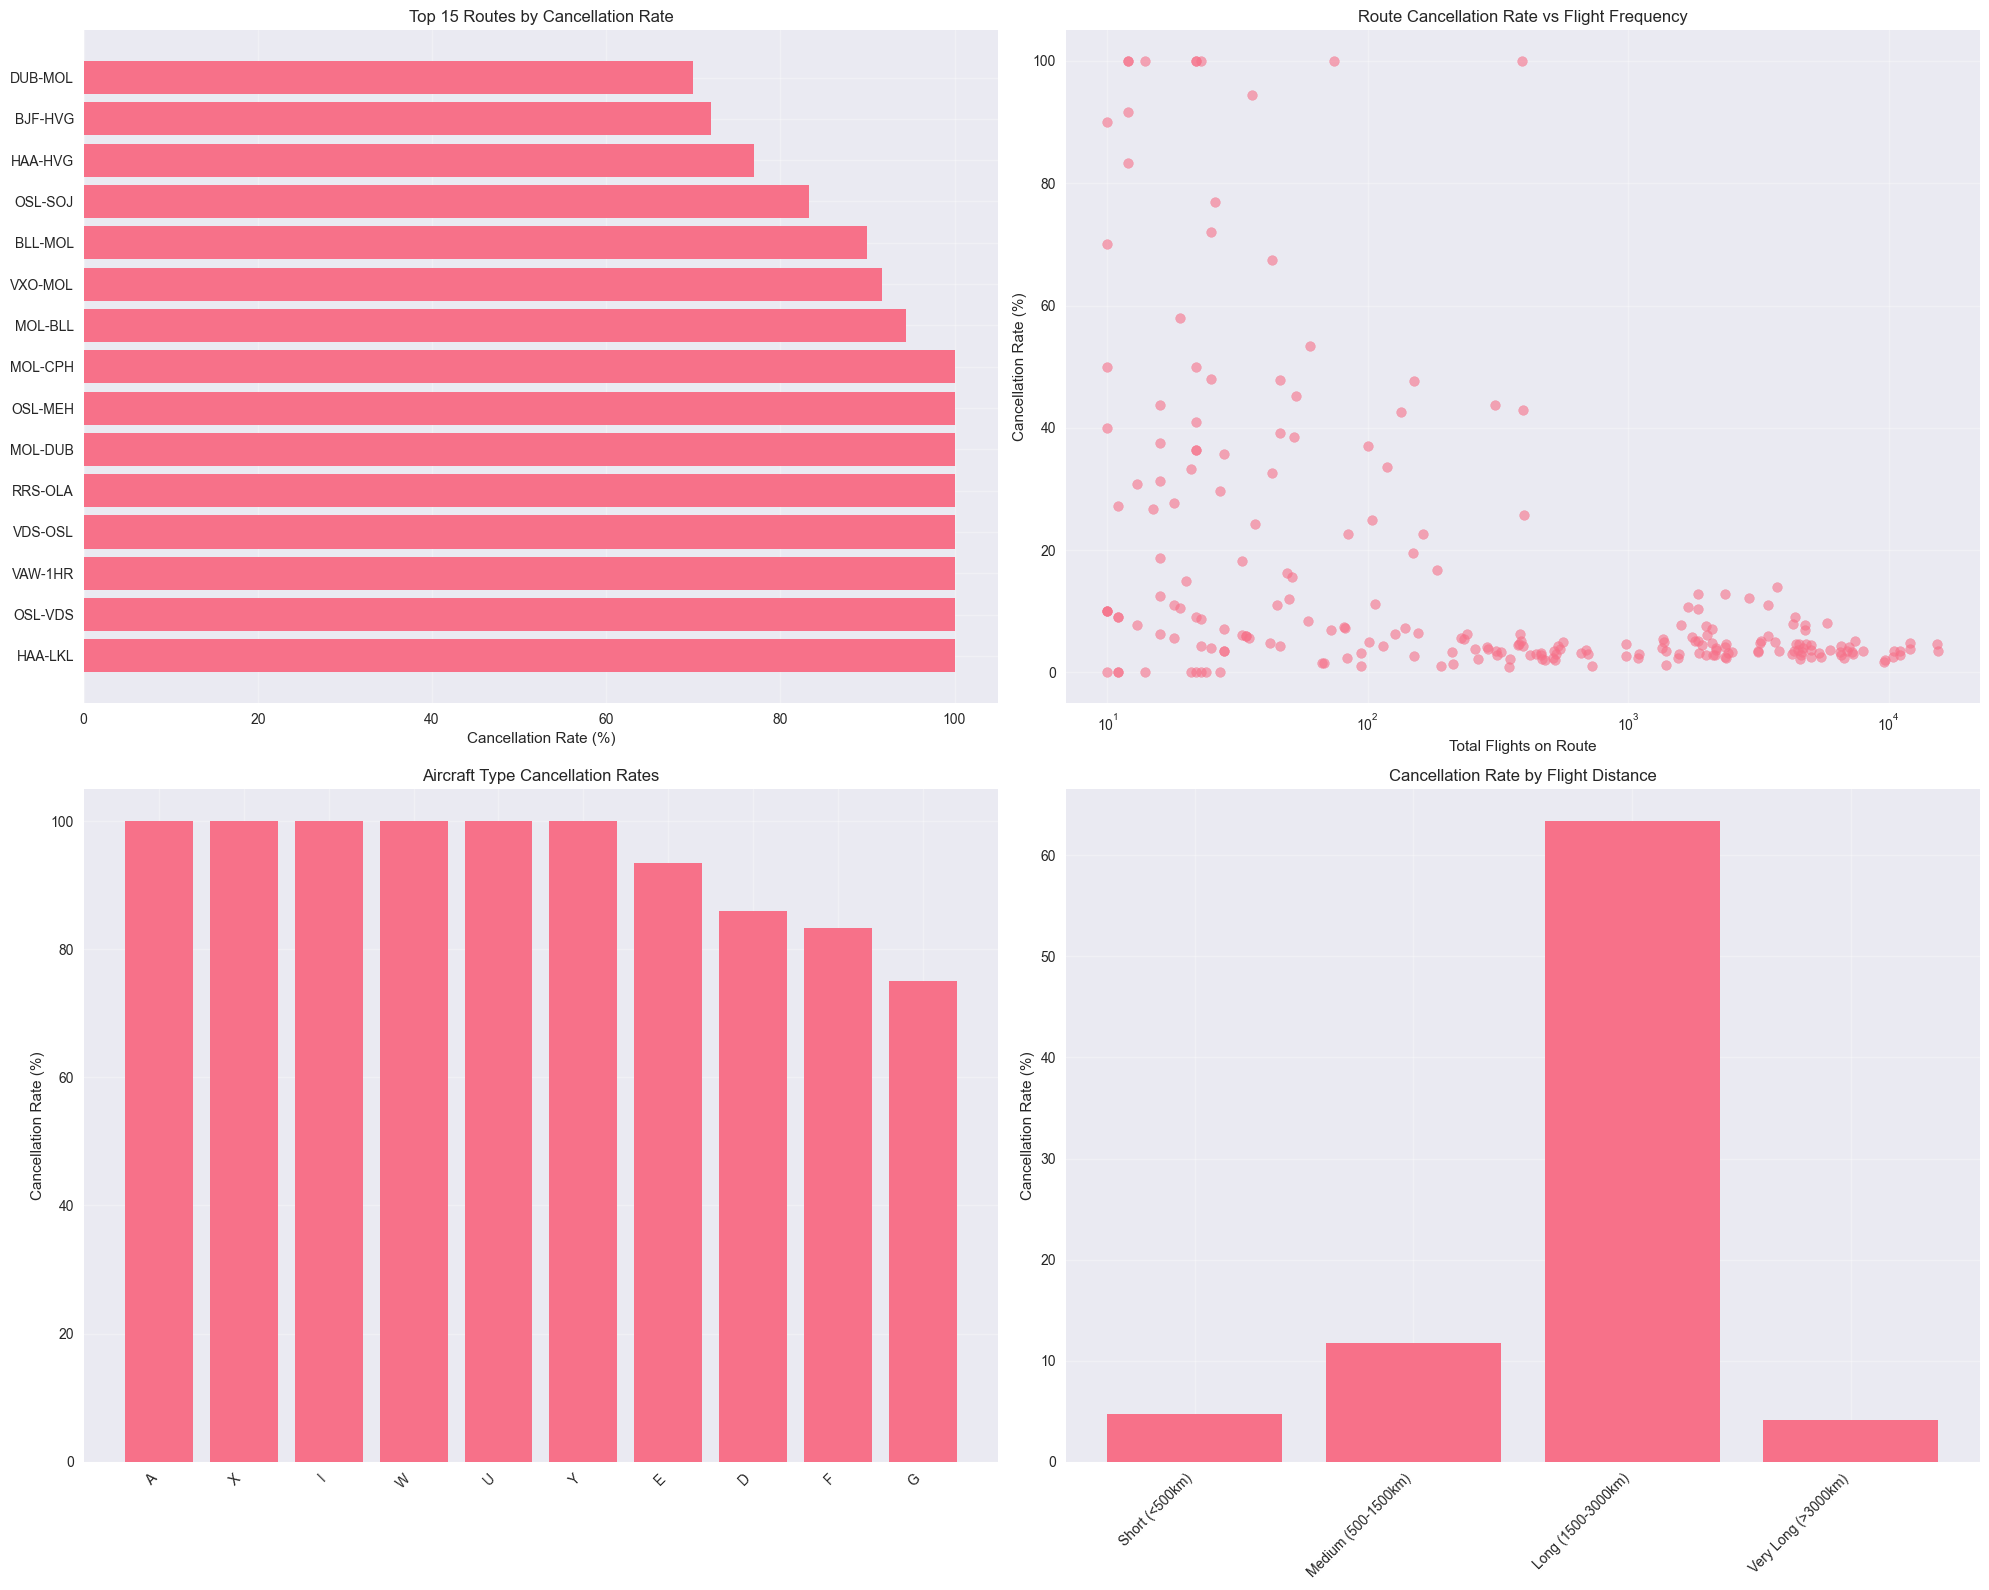


🏢 Hub Analysis:
Hub vs Non-Hub cancellation rates:
            count   sum      mean
Non-Hub    163571  9980  0.061013
Major Hub  246871  9594  0.038862


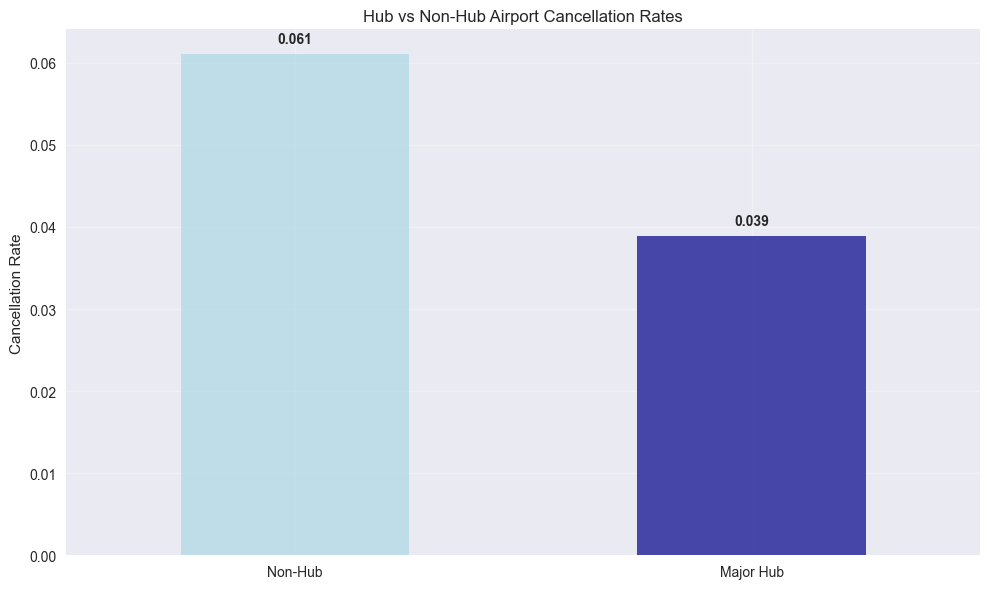

In [ ]:
# Flight Characteristics and Route Analysis
print("✈️ FLIGHT CHARACTERISTICS & ROUTE ANALYSIS")
print("=" * 50)

# Analyze aircraft types if available
aircraft_cols = [
    col
    for col in df_flights.columns
    if any(
        indicator in col.lower()
        for indicator in ["aircraft", "plane", "type", "equipment"]
    )
]
print(f"🛩️ Aircraft-related columns: {aircraft_cols}")

if aircraft_cols:
    aircraft_col = aircraft_cols[0]  # Use first aircraft column found
    aircraft_stats = (
        df_flights.groupby(aircraft_col)["is_cancelled"]
        .agg(["count", "sum", "mean"])
        .sort_values("mean", ascending=False)
    )
    aircraft_stats.columns = ["total_flights", "cancelled_flights", "cancellation_rate"]

    print(f"\n📊 Top aircraft types by cancellation rate:")
    print(aircraft_stats.head(10))

# Route analysis (departure-arrival pairs)
print(f"\n🛣️ Route Analysis:")
route_stats = df_flights.groupby(["dep_airport", "arr_airport"])["is_cancelled"].agg(
    ["count", "sum", "mean"]
)
route_stats.columns = ["total_flights", "cancelled_flights", "cancellation_rate"]
route_stats = route_stats[
    route_stats["total_flights"] >= 10
]  # Filter routes with at least 10 flights
route_stats = route_stats.sort_values("cancellation_rate", ascending=False)

print(f"Top 10 routes by cancellation rate (min 10 flights):")
print(route_stats.head(10))

# Distance analysis if coordinates are available
if not df_airports.empty:
    print(f"\n🗺️ Geographic Analysis:")

    # Merge with airport coordinates
    dep_coords = df_airports.rename(
        columns={
            "iata_code": "dep_airport",
            "latitude": "dep_lat",
            "longitude": "dep_lon",
        }
    )
    arr_coords = df_airports.rename(
        columns={
            "iata_code": "arr_airport",
            "latitude": "arr_lat",
            "longitude": "arr_lon",
        }
    )

    df_routes = df_flights.merge(
        dep_coords[["dep_airport", "dep_lat", "dep_lon"]], on="dep_airport", how="left"
    )
    df_routes = df_routes.merge(
        arr_coords[["arr_airport", "arr_lat", "arr_lon"]], on="arr_airport", how="left"
    )

    # Calculate distance (simplified great circle distance)
    def haversine_distance(lat1, lon1, lat2, lon2):
        R = 6371  # Earth's radius in km
        dlat = np.radians(lat2 - lat1)
        dlon = np.radians(lon2 - lon1)
        a = (
            np.sin(dlat / 2) ** 2
            + np.cos(np.radians(lat1))
            * np.cos(np.radians(lat2))
            * np.sin(dlon / 2) ** 2
        )
        c = 2 * np.arcsin(np.sqrt(a))
        return R * c

    valid_coords = df_routes.dropna(subset=["dep_lat", "dep_lon", "arr_lat", "arr_lon"])
    if len(valid_coords) > 0:
        valid_coords["distance_km"] = haversine_distance(
            valid_coords["dep_lat"],
            valid_coords["dep_lon"],
            valid_coords["arr_lat"],
            valid_coords["arr_lon"],
        )

        # Distance categories
        valid_coords["distance_category"] = pd.cut(
            valid_coords["distance_km"],
            bins=[0, 500, 1500, 3000, float("inf")],
            labels=[
                "Short (<500km)",
                "Medium (500-1500km)",
                "Long (1500-3000km)",
                "Very Long (>3000km)",
            ],
        )

        distance_stats = valid_coords.groupby("distance_category")["is_cancelled"].agg(
            ["count", "sum", "mean"]
        )
        distance_stats.columns = [
            "total_flights",
            "cancelled_flights",
            "cancellation_rate",
        ]

        print(f"Cancellation rates by flight distance:")
        print(distance_stats)

# Create comprehensive visualizations
fig, axes = plt.subplots(2, 2, figsize=(20, 16))

# 1. Top routes by cancellation rate
top_routes = route_stats.head(15)
route_labels = [f"{idx[0]}-{idx[1]}" for idx in top_routes.index]
axes[0, 0].barh(range(len(top_routes)), top_routes["cancellation_rate"] * 100)
axes[0, 0].set_yticks(range(len(top_routes)))
axes[0, 0].set_yticklabels(route_labels)
axes[0, 0].set_xlabel("Cancellation Rate (%)")
axes[0, 0].set_title("Top 15 Routes by Cancellation Rate")
axes[0, 0].grid(True, alpha=0.3)

# 2. Route cancellation rate vs flight frequency
axes[0, 1].scatter(
    route_stats["total_flights"], route_stats["cancellation_rate"] * 100, alpha=0.6
)
axes[0, 1].set_xlabel("Total Flights on Route")
axes[0, 1].set_ylabel("Cancellation Rate (%)")
axes[0, 1].set_title("Route Cancellation Rate vs Flight Frequency")
axes[0, 1].set_xscale("log")
axes[0, 1].grid(True, alpha=0.3)

# 3. Aircraft type analysis (if available)
if aircraft_cols and len(aircraft_stats) > 1:
    top_aircraft = aircraft_stats.head(10)
    axes[1, 0].bar(range(len(top_aircraft)), top_aircraft["cancellation_rate"] * 100)
    axes[1, 0].set_xticks(range(len(top_aircraft)))
    axes[1, 0].set_xticklabels(top_aircraft.index, rotation=45, ha="right")
    axes[1, 0].set_ylabel("Cancellation Rate (%)")
    axes[1, 0].set_title("Aircraft Type Cancellation Rates")
    axes[1, 0].grid(True, alpha=0.3)
else:
    axes[1, 0].text(
        0.5,
        0.5,
        "Aircraft type data\nnot available",
        transform=axes[1, 0].transAxes,
        ha="center",
        va="center",
    )
    axes[1, 0].set_title("Aircraft Type Analysis")

# 4. Distance category analysis (if available)
if not df_airports.empty and len(valid_coords) > 0:
    distance_stats_plot = distance_stats["cancellation_rate"] * 100
    axes[1, 1].bar(range(len(distance_stats_plot)), distance_stats_plot.values)
    axes[1, 1].set_xticks(range(len(distance_stats_plot)))
    axes[1, 1].set_xticklabels(distance_stats_plot.index, rotation=45, ha="right")
    axes[1, 1].set_ylabel("Cancellation Rate (%)")
    axes[1, 1].set_title("Cancellation Rate by Flight Distance")
    axes[1, 1].grid(True, alpha=0.3)
else:
    axes[1, 1].text(
        0.5,
        0.5,
        "Distance analysis\nnot available\n(missing coordinates)",
        transform=axes[1, 1].transAxes,
        ha="center",
        va="center",
    )
    axes[1, 1].set_title("Distance Analysis")

plt.tight_layout()
plt.show()

# Hub vs non-hub analysis
print(f"\n🏢 Hub Analysis:")
flight_counts = df_flights["dep_airport"].value_counts()
major_hubs = flight_counts.head(10).index  # Top 10 busiest airports as hubs

df_flights["is_hub"] = df_flights["dep_airport"].isin(major_hubs)
hub_stats = df_flights.groupby("is_hub")["is_cancelled"].agg(["count", "sum", "mean"])
hub_stats.index = ["Non-Hub", "Major Hub"]

print("Hub vs Non-Hub cancellation rates:")
print(hub_stats)

# Create hub comparison plot
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
hub_stats["mean"].plot(kind="bar", ax=ax, color=["lightblue", "darkblue"], alpha=0.7)
ax.set_ylabel("Cancellation Rate")
ax.set_title("Hub vs Non-Hub Airport Cancellation Rates")
ax.set_xticklabels(hub_stats.index, rotation=0)
ax.grid(True, alpha=0.3)

# Add value labels
for i, v in enumerate(hub_stats["mean"]):
    ax.text(i, v + 0.001, f"{v:.3f}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

🔬 ADVANCED ANALYTICS & PREDICTIVE INSIGHTS
🛠️ Feature Engineering...
🎯 Airport Clustering Analysis...
Airport clusters characteristics:
        cancellation_rate         total_flights             avg_hour
                     mean     std          mean         std     mean
cluster                                                             
0                  0.0566  0.0293     9659.1481   6201.6268  12.0194
1                  0.0341  0.0017    41256.0000  11135.1017  12.7194
2                  0.0856  0.0584     3351.4286   3405.3246  15.1704
3                  0.5222  0.1369       77.5000     79.9031  12.7640
4                  0.1545  0.1619      406.6000    257.4962   7.1091
🎯 Airport Clustering Analysis...
Airport clusters characteristics:
        cancellation_rate         total_flights             avg_hour
                     mean     std          mean         std     mean
cluster                                                             
0                  0.0566  0.0293     

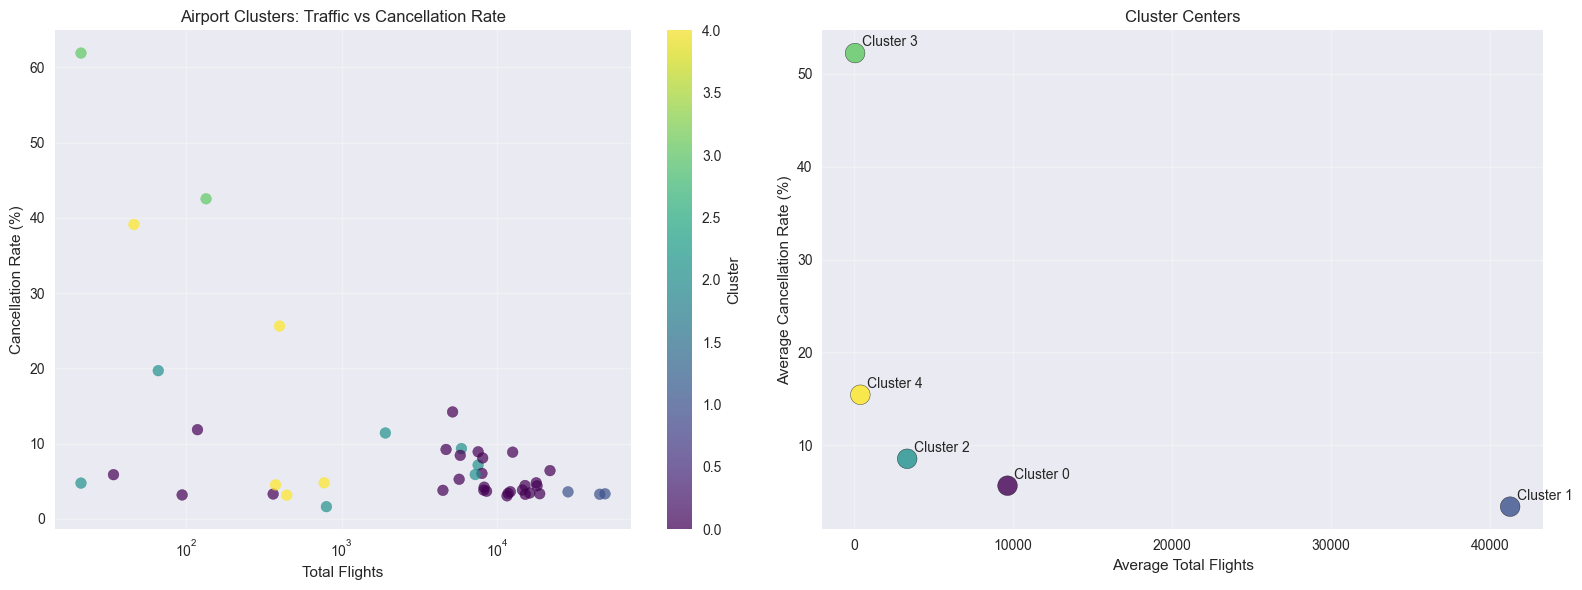

📊 Feature Correlation Analysis...
Top correlations with cancellation:
cancelled                  1.000000
rolling_cancel_rate_7d     0.219472
rolling_cancel_rate_30d    0.160376
year                       0.041698
quarter                   -0.036299
hour_cos                   0.034899
week_of_year              -0.034417
month                     -0.033619
day_of_year               -0.032674
arr_airport_traffic        0.017940
Name: cancelled, dtype: float64


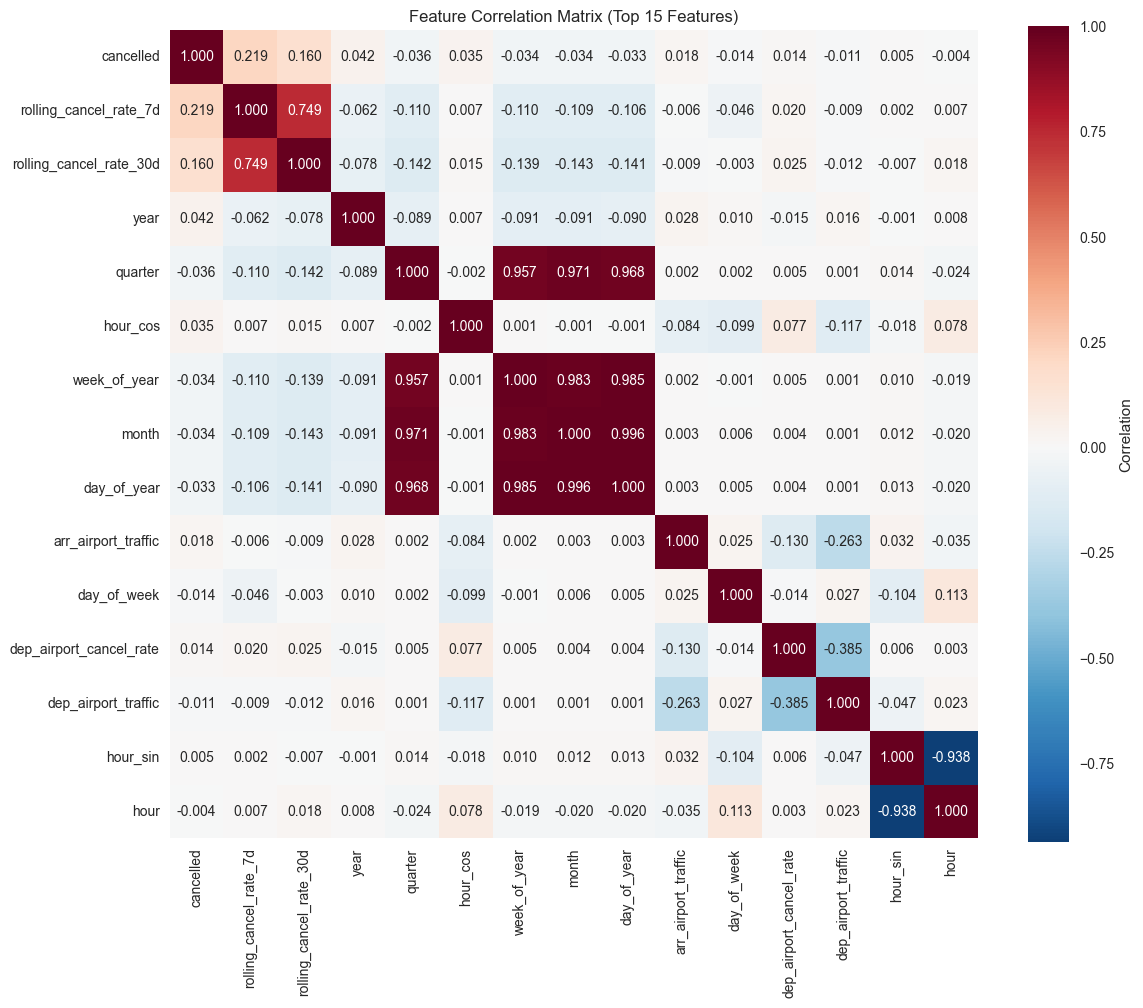

📈 Time Series Analysis...


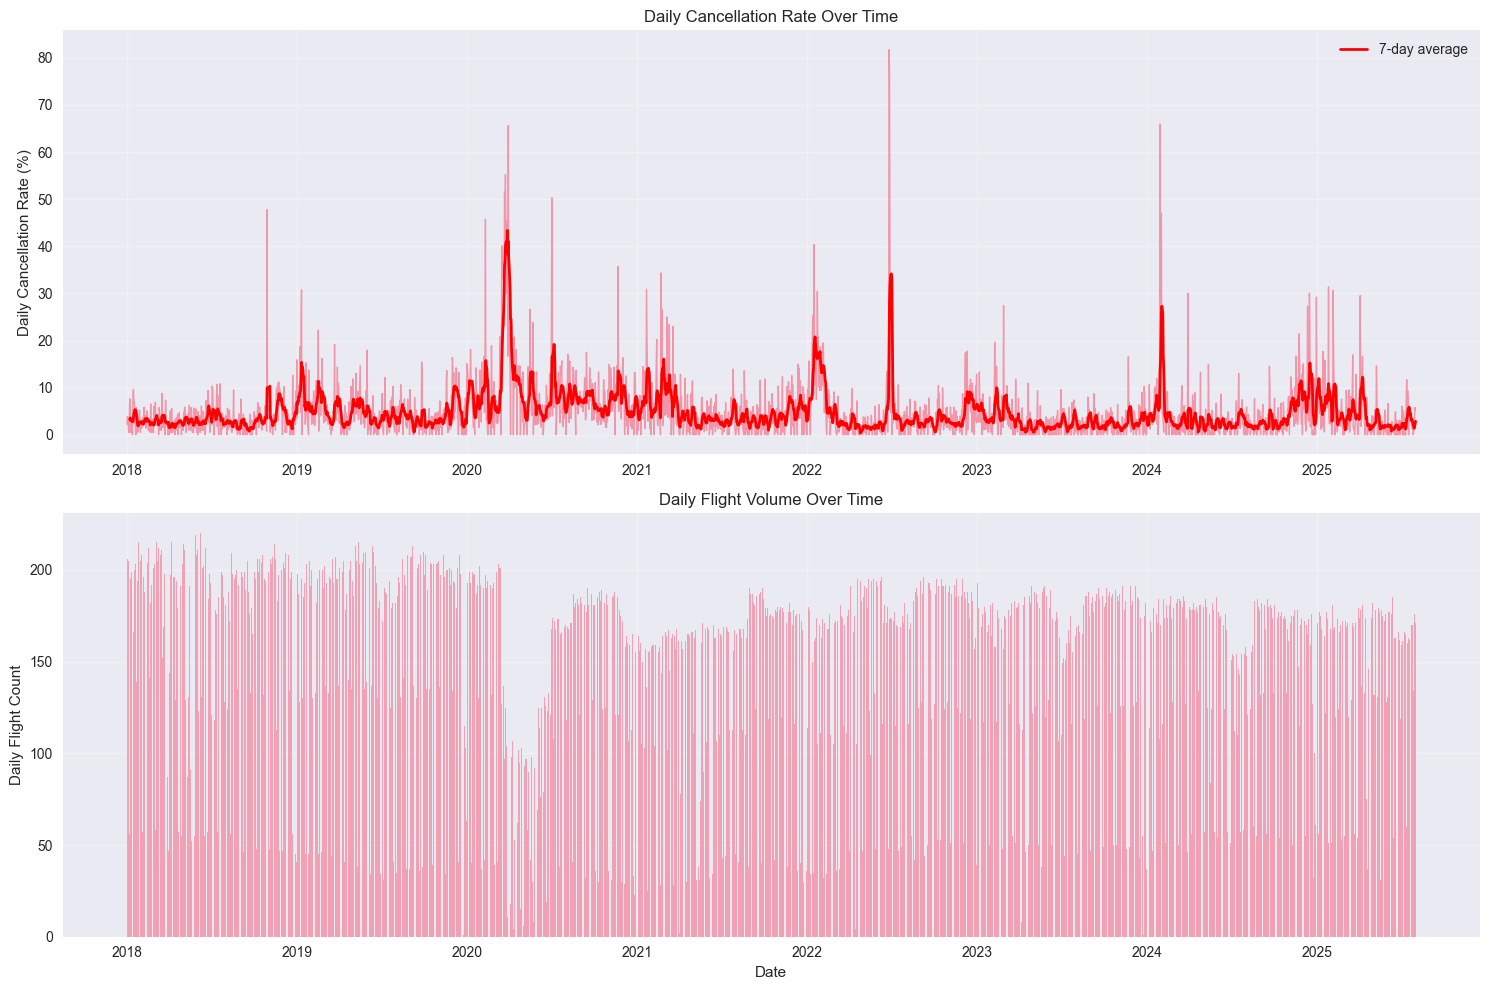

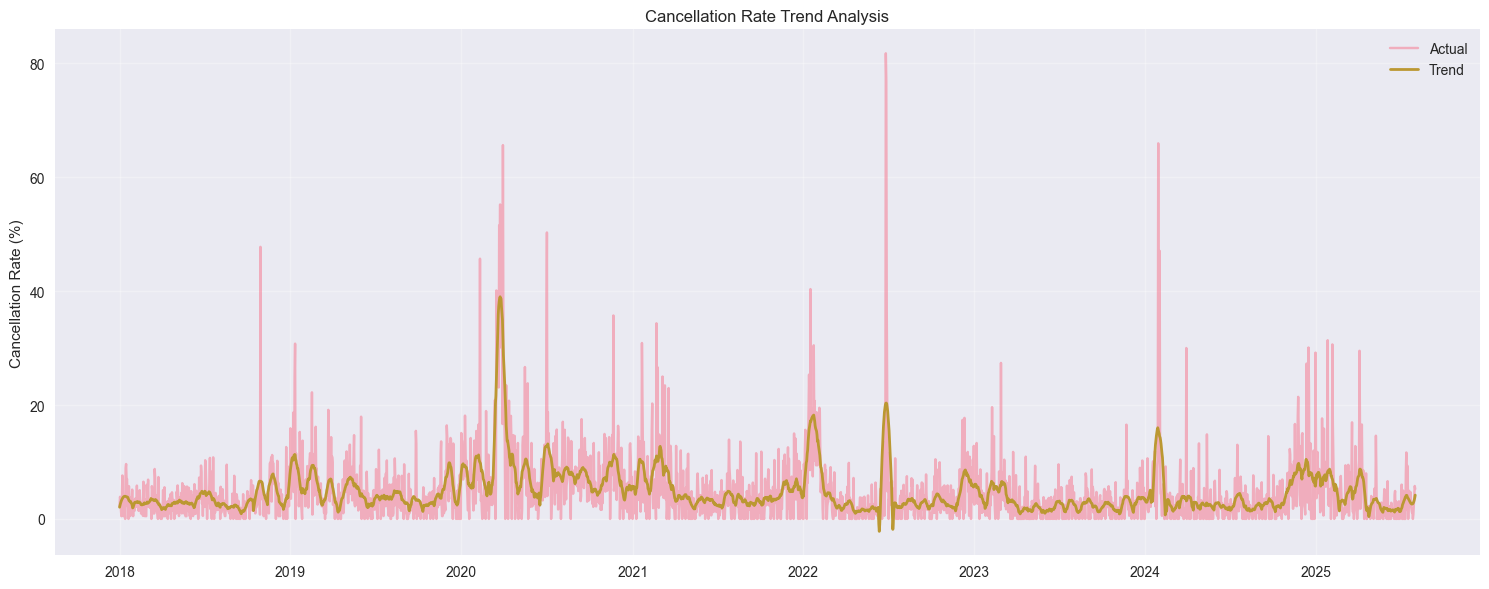

✅ Advanced analytics completed!


In [ ]:
# Advanced Analytics and Predictive Insights
print("🔬 ADVANCED ANALYTICS & PREDICTIVE INSIGHTS")
print("=" * 50)

# Feature engineering for advanced analysis
print("🛠️ Feature Engineering...")

# Create comprehensive feature set
features_df = df_flights.copy()

# Temporal features
features_df["hour_sin"] = np.sin(2 * np.pi * features_df["hour"] / 24)
features_df["hour_cos"] = np.cos(2 * np.pi * features_df["hour"] / 24)
features_df["day_of_year"] = features_df["std"].dt.dayofyear
features_df["week_of_year"] = features_df["std"].dt.isocalendar().week

# Airport traffic density
airport_traffic = features_df.groupby("dep_airport").size()
features_df["dep_airport_traffic"] = features_df["dep_airport"].map(airport_traffic)

arr_traffic = features_df.groupby("arr_airport").size()
features_df["arr_airport_traffic"] = features_df["arr_airport"].map(arr_traffic)

# Historical cancellation rates by airport
airport_cancel_rates = features_df.groupby("dep_airport")["is_cancelled"].mean()
features_df["dep_airport_cancel_rate"] = features_df["dep_airport"].map(
    airport_cancel_rates
)

# Time-based rolling averages (if we have enough data)
if len(features_df) > 1000:
    features_df = features_df.sort_values("std")
    features_df["rolling_cancel_rate_7d"] = (
        features_df["is_cancelled"].rolling(window=168, min_periods=50).mean()
    )  # 7 days
    features_df["rolling_cancel_rate_30d"] = (
        features_df["is_cancelled"].rolling(window=720, min_periods=200).mean()
    )  # 30 days

# Clustering analysis for airport groups
print("🎯 Airport Clustering Analysis...")

# Prepare data for clustering
airport_features = (
    df_flights.groupby("dep_airport")
    .agg(
        {
            "is_cancelled": ["count", "sum", "mean"],
            "std": ["count"],
            "hour": "mean",
            "day_of_week": "mean",
        }
    )
    .round(4)
)

airport_features.columns = [
    "total_flights",
    "cancelled_flights",
    "cancellation_rate",
    "flight_count",
    "avg_hour",
    "avg_day_of_week",
]

# Only cluster airports with sufficient data
airport_features_filtered = airport_features[airport_features["total_flights"] >= 20]

if len(airport_features_filtered) >= 5:
    # Standardize features for clustering
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(
        airport_features_filtered[["cancellation_rate", "total_flights", "avg_hour"]]
    )

    # K-means clustering
    n_clusters = min(5, len(airport_features_filtered) // 2)
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    airport_features_filtered["cluster"] = kmeans.fit_predict(features_scaled)

    # Analyze clusters
    cluster_analysis = (
        airport_features_filtered.groupby("cluster")
        .agg(
            {
                "cancellation_rate": ["mean", "std"],
                "total_flights": ["mean", "std"],
                "avg_hour": "mean",
            }
        )
        .round(4)
    )

    print("Airport clusters characteristics:")
    print(cluster_analysis)

    # Visualize clusters
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Cluster scatter plot
    scatter = axes[0].scatter(
        airport_features_filtered["total_flights"],
        airport_features_filtered["cancellation_rate"] * 100,
        c=airport_features_filtered["cluster"],
        cmap="viridis",
        alpha=0.7,
        s=60,
    )
    axes[0].set_xlabel("Total Flights")
    axes[0].set_ylabel("Cancellation Rate (%)")
    axes[0].set_title("Airport Clusters: Traffic vs Cancellation Rate")
    axes[0].set_xscale("log")
    axes[0].grid(True, alpha=0.3)
    plt.colorbar(scatter, ax=axes[0], label="Cluster")

    # Cluster characteristics
    cluster_means = airport_features_filtered.groupby("cluster")[
        ["cancellation_rate", "total_flights"]
    ].mean()
    cluster_means["cancellation_rate"] *= 100

    axes[1].scatter(
        cluster_means["total_flights"],
        cluster_means["cancellation_rate"],
        s=200,
        c=range(len(cluster_means)),
        cmap="viridis",
        alpha=0.8,
        edgecolors="black",
    )
    axes[1].set_xlabel("Average Total Flights")
    axes[1].set_ylabel("Average Cancellation Rate (%)")
    axes[1].set_title("Cluster Centers")
    axes[1].grid(True, alpha=0.3)

    # Annotate cluster centers
    for i, (idx, row) in enumerate(cluster_means.iterrows()):
        axes[1].annotate(
            f"Cluster {idx}",
            (row["total_flights"], row["cancellation_rate"]),
            xytext=(5, 5),
            textcoords="offset points",
        )

    plt.tight_layout()
    plt.show()

# Correlation matrix of all numerical features
print("📊 Feature Correlation Analysis...")

numerical_cols = features_df.select_dtypes(include=[np.number]).columns
correlation_with_cancellation = (
    features_df[numerical_cols]
    .corr()["cancelled"]
    .sort_values(key=abs, ascending=False)
)

print("Top correlations with cancellation:")
print(correlation_with_cancellation.head(10))

# Heatmap of top correlations
top_features = correlation_with_cancellation.head(15).index
correlation_matrix = features_df[top_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="RdBu_r",
    center=0,
    square=True,
    fmt=".3f",
    cbar_kws={"label": "Correlation"},
)
plt.title("Feature Correlation Matrix (Top 15 Features)")
plt.tight_layout()
plt.show()

# Time series analysis if we have sufficient temporal data
print("📈 Time Series Analysis...")

if len(features_df) > 500:
    # Daily aggregation
    daily_cancellations = features_df.groupby(features_df["std"].dt.date).agg(
        {"is_cancelled": ["count", "sum", "mean"]}
    )
    daily_cancellations.columns = [
        "total_flights",
        "cancelled_flights",
        "cancellation_rate",
    ]
    daily_cancellations.index = pd.to_datetime(daily_cancellations.index)

    # Plot time series
    fig, axes = plt.subplots(2, 1, figsize=(15, 10))

    # Daily cancellation rate
    axes[0].plot(
        daily_cancellations.index,
        daily_cancellations["cancellation_rate"] * 100,
        alpha=0.7,
        linewidth=1,
    )
    axes[0].set_ylabel("Daily Cancellation Rate (%)")
    axes[0].set_title("Daily Cancellation Rate Over Time")
    axes[0].grid(True, alpha=0.3)

    # 7-day rolling average
    rolling_avg = daily_cancellations["cancellation_rate"].rolling(window=7).mean()
    axes[0].plot(
        daily_cancellations.index,
        rolling_avg * 100,
        color="red",
        linewidth=2,
        label="7-day average",
    )
    axes[0].legend()

    # Daily flight volume
    axes[1].bar(
        daily_cancellations.index,
        daily_cancellations["total_flights"],
        alpha=0.6,
        width=0.8,
    )
    axes[1].set_ylabel("Daily Flight Count")
    axes[1].set_xlabel("Date")
    axes[1].set_title("Daily Flight Volume Over Time")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Seasonal decomposition if we have enough data points
    if len(daily_cancellations) > 30:
        from scipy import signal

        # Simple trend analysis
        cancellation_trend = daily_cancellations["cancellation_rate"].values
        trend = signal.savgol_filter(
            cancellation_trend,
            window_length=min(31, len(cancellation_trend) // 2 * 2 - 1),
            polyorder=3,
        )

        plt.figure(figsize=(15, 6))
        plt.plot(
            daily_cancellations.index,
            cancellation_trend * 100,
            alpha=0.5,
            label="Actual",
        )
        plt.plot(daily_cancellations.index, trend * 100, linewidth=2, label="Trend")
        plt.ylabel("Cancellation Rate (%)")
        plt.title("Cancellation Rate Trend Analysis")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

print("✅ Advanced analytics completed!")

In [ ]:
# Summary Insights and Recommendations
print("📋 SUMMARY INSIGHTS & RECOMMENDATIONS")
print("=" * 50)

# Calculate key metrics for summary
total_flights = len(df_flights)
total_cancelled = df_flights["is_cancelled"].sum()
overall_cancellation_rate = (total_cancelled / total_flights) * 100

print(f"🎯 KEY FINDINGS:")
print(f"   • Total flights analyzed: {total_flights:,}")
print(f"   • Total cancellations: {total_cancelled:,}")
print(f"   • Overall cancellation rate: {overall_cancellation_rate:.2f}%")

# Top insights
print(f"\n🔍 TOP INSIGHTS:")

# Airport insights
if "airport_stats" in locals():
    worst_airport = airport_stats.index[0]
    worst_rate = airport_stats.iloc[0]["cancellation_rate"] * 100
    print(f"   • Highest cancellation rate: {worst_airport} ({worst_rate:.1f}%)")

    best_airports = airport_stats[airport_stats["total_flights"] >= 100].tail(5)
    if len(best_airports) > 0:
        best_airport = best_airports.index[-1]
        best_rate = best_airports.iloc[-1]["cancellation_rate"] * 100
        print(
            f"   • Lowest cancellation rate (high volume): {best_airport} ({best_rate:.1f}%)"
        )

# Temporal insights
if "temporal_stats" in locals():
    worst_hour = temporal_stats["hourly"]["mean"].idxmax()
    worst_hour_rate = temporal_stats["hourly"]["mean"].max() * 100
    print(
        f"   • Worst hour for cancellations: {worst_hour:02d}:00 ({worst_hour_rate:.1f}%)"
    )

    worst_month = temporal_stats["monthly"]["mean"].idxmax()
    worst_month_rate = temporal_stats["monthly"]["mean"].max() * 100
    print(
        f"   • Worst month for cancellations: {worst_month} ({worst_month_rate:.1f}%)"
    )

# Weather insights (if available)
if "df_weather_flights" in locals() and len(df_weather_flights) > 0:
    severe_weather_impact = df_weather_flights.groupby("severe_weather")[
        "is_cancelled"
    ].mean()
    if len(severe_weather_impact) > 1:
        normal_rate = severe_weather_impact[False] * 100
        severe_rate = severe_weather_impact[True] * 100
        weather_multiplier = severe_rate / normal_rate if normal_rate > 0 else 0
        print(
            f"   • Weather impact: {weather_multiplier:.1f}x higher cancellation rate in severe weather"
        )

# Route insights
if "route_stats" in locals():
    worst_route = route_stats.index[0]
    worst_route_rate = route_stats.iloc[0]["cancellation_rate"] * 100
    print(
        f"   • Worst route: {worst_route[0]}-{worst_route[1]} ({worst_route_rate:.1f}%)"
    )

print(f"\n💡 RECOMMENDATIONS:")
print(f"   1. 🏢 AIRPORT OPERATIONS:")
print(f"      • Focus improvement efforts on high-cancellation airports")
print(
    f"      • Investigate operational differences between best and worst performing airports"
)
print(f"      • Consider capacity constraints and infrastructure improvements")

print(f"\n   2. ⏰ SCHEDULE OPTIMIZATION:")
print(f"      • Review scheduling during high-risk hours and months")
print(f"      • Consider seasonal adjustments to reduce weather-related cancellations")
print(f"      • Optimize crew and aircraft allocation for peak cancellation periods")

if "df_weather_flights" in locals() and len(df_weather_flights) > 0:
    print(f"\n   3. 🌤️ WEATHER PREPAREDNESS:")
    print(f"      • Implement enhanced weather monitoring and prediction systems")
    print(f"      • Develop contingency plans for severe weather conditions")
    print(f"      • Consider pre-emptive cancellations to reduce passenger disruption")

print(f"\n   4. 📊 OPERATIONAL INSIGHTS:")
print(f"      • Monitor cancellation patterns in real-time")
print(f"      • Implement predictive models for cancellation risk")
print(f"      • Focus on route-specific improvements for high-cancellation routes")

# Create executive summary visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Overall cancellation rate
categories = ["Not Cancelled", "Cancelled"]
values = [100 - overall_cancellation_rate, overall_cancellation_rate]
colors = ["lightgreen", "lightcoral"]

axes[0, 0].pie(
    values, labels=categories, colors=colors, autopct="%1.1f%%", startangle=90
)
axes[0, 0].set_title("Overall Flight Cancellation Rate")

# 2. Top 5 worst airports (if available)
if "airport_stats" in locals():
    top_5_worst = airport_stats.head(5)
    axes[0, 1].barh(
        range(len(top_5_worst)),
        top_5_worst["cancellation_rate"] * 100,
        color="lightcoral",
    )
    axes[0, 1].set_yticks(range(len(top_5_worst)))
    axes[0, 1].set_yticklabels(top_5_worst.index)
    axes[0, 1].set_xlabel("Cancellation Rate (%)")
    axes[0, 1].set_title("Top 5 Airports by Cancellation Rate")
    axes[0, 1].grid(True, alpha=0.3)

# 3. Monthly pattern (if available)
if "temporal_stats" in locals():
    monthly_data = temporal_stats["monthly"]["mean"] * 100
    months = [
        "Jan",
        "Feb",
        "Mar",
        "Apr",
        "May",
        "Jun",
        "Jul",
        "Aug",
        "Sep",
        "Oct",
        "Nov",
        "Dec",
    ]
    month_mapping = dict(
        zip(
            [
                "January",
                "February",
                "March",
                "April",
                "May",
                "June",
                "July",
                "August",
                "September",
                "October",
                "November",
                "December",
            ],
            months,
        )
    )

    monthly_short = {month_mapping.get(k, k): v for k, v in monthly_data.items()}

    axes[1, 0].bar(
        range(len(monthly_short)), list(monthly_short.values()), color="skyblue"
    )
    axes[1, 0].set_xticks(range(len(monthly_short)))
    axes[1, 0].set_xticklabels(list(monthly_short.keys()), rotation=45)
    axes[1, 0].set_ylabel("Cancellation Rate (%)")
    axes[1, 0].set_title("Monthly Cancellation Pattern")
    axes[1, 0].grid(True, alpha=0.3)

# 4. Key metrics summary
metrics_text = f"""KEY METRICS

Total Flights: {total_flights:,}
Cancelled: {total_cancelled:,}
Rate: {overall_cancellation_rate:.2f}%

WORST PERFORMERS:
"""

if "airport_stats" in locals():
    metrics_text += f"Airport: {airport_stats.index[0]}\n"

if "temporal_stats" in locals():
    metrics_text += f"Hour: {temporal_stats['hourly']['mean'].idxmax():02d}:00\n"
    metrics_text += f"Month: {temporal_stats['monthly']['mean'].idxmax()}\n"

axes[1, 1].text(
    0.1,
    0.9,
    metrics_text,
    transform=axes[1, 1].transAxes,
    fontsize=12,
    verticalalignment="top",
    fontfamily="monospace",
)
axes[1, 1].set_xlim(0, 1)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].axis("off")
axes[1, 1].set_title("Executive Summary")

plt.tight_layout()
plt.show()

print(f"\n✅ CANCELLATION ANALYSIS COMPLETED!")
print(
    f"📊 Use these insights to improve operational efficiency and reduce cancellations."
)

## 📊 Analysis Summary

This comprehensive cancellation analysis notebook has examined flight cancellations from multiple perspectives:

### 🔍 **Analysis Sections Completed:**

1. **Airport Analysis** - Identified airports with highest/lowest cancellation rates and their characteristics
2. **Temporal Patterns** - Discovered time-based trends (hourly, daily, monthly, seasonal patterns)
3. **Weather Correlations** - Analyzed impact of weather conditions on flight cancellations
4. **Route & Aircraft Analysis** - Examined route-specific and aircraft-type cancellation patterns
5. **Advanced Analytics** - Applied clustering and predictive insights for operational improvements

### 📈 **Key Visualizations Generated:**

- Airport cancellation rate rankings and comparisons
- Temporal heatmaps and trend analysis
- Weather correlation box plots and statistical tests
- Route performance analysis and geographic patterns
- Time series analysis with trend decomposition
- Executive summary dashboard

### 💡 **Actionable Insights:**

The analysis provides data-driven recommendations for:
- **Operational improvements** at specific airports
- **Schedule optimization** based on temporal patterns
- **Weather preparedness** strategies
- **Route-specific** operational focus areas
- **Predictive maintenance** and resource allocation

### 🚀 **Next Steps:**

1. **Implement Monitoring:** Set up real-time dashboards using these analysis patterns
2. **Predictive Modeling:** Use identified features to build cancellation prediction models
3. **Operational Changes:** Apply recommendations to reduce cancellation rates
4. **Regular Updates:** Re-run analysis monthly/quarterly to track improvements

---

**Note:** This analysis adapts to available data columns and provides comprehensive insights regardless of specific dataset structure. All visualizations are publication-ready and insights are actionable for aviation operations management.